# M13a · Vraisemblance et régression logistique — solutions (notebook exécuté)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cemah2/workbookMaths/blob/main/chapitres/m13a_vraisemblance_logistique/05_solutions.ipynb)

Les réponses des exercices, exécutées. Les démarches détaillées (le *pourquoi*, les erreurs fréquentes, les variantes) sont dans `05_solutions.md`. Les cellules marquées `answer` enregistrent les réponses vérifiées par `wbm.check` (`tools/build_answers.py`).

| Partie | ID | Titre | Type | ★ | ⏱️ |
|---|---|---|---|---|---|
| 0 | M13a.1 à M13a.12, M13a.18 | Les exercices papier (vérification) | ✏️ 🔗 | | |
| A | M13a.22 | La log-vraisemblance et le maximum de vraisemblance d'une loi de Bernoulli · `bernoulli_log_likelihood, bernoulli_mle` | 🔨 | ★ | 15 |
|  | M13a.23 | Maximum de vraisemblance catégoriel, avec lissage, et gaussien · `categorical_mle, gaussian_mle` | 🔨 | ★ | 20 |
|  | M13a.24 | La log-loss à partir des scores, sans débordement · `logistic_loss` | 🔨 | ★★ | 20 |
|  | M13a.25 | `scipy.stats`, `scipy.special` et `sklearn.metrics.log_loss` contre tes fonctions | 📦 | ★ | 25 |
| B | M13a.26 | Prédire la log-loss d'un modèle qui répond toujours 0,5, puis toujours la fréquence des 1 | 🔮 | ★ | 10 |
|  | M13a.27 | La variabilité du maximum de vraisemblance d'une loi de Bernoulli d'un échantillon à l'autre | 🔬 | ★★ | 20 |
|  | M13a.28 | L'entropie et l'indice de Gini sur les lois à trois issues : lignes de niveau et maximum au centre | 🎨 | ★ | 25 |
| C | M13a.29 | Chasse à l'erreur : un ln 0, une sigmoïde qui déborde, une variance de maximum de vraisemblance divisée par n − 1 | 🐛 | ★ | 15 |
|  | M13a.30 | Vérifier avec SymPy le maximum de vraisemblance d'une loi géométrique et d'une loi de Poisson | 🛠️ | ★ | 15 |
|  | M13a.31 | Défi : la proportion d'un mélange de deux lois connues par maximum de vraisemblance, à 1e−6 près du maximum (dichotomie ou Newton) | 🏆 | ★★★ | 25 |

In [1]:
# ⚙️ SETUP: run this cell first (on Colab or on your computer)
FAST_MODE = True  # True = quick version (a few seconds per cell); False = bigger experiments
SEED = 42

import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/cemah2/workbookMaths.git"
DRIVE_DIR = Path("/content/drive/MyDrive/workbookMaths")

try:
    import google.colab  # noqa: F401  (this module only exists on Colab)
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    subprocess.run(["git", "config", "--global", "--add", "safe.directory", str(DRIVE_DIR)])
    if not (DRIVE_DIR / ".git").exists():
        subprocess.run(["git", "clone", REPO_URL, str(DRIVE_DIR)], check=True)
    else:
        # Get the new chapters. Your own work only lives in mon_travail/, which Claude never
        # touches, so "rebase + autostash" keeps it safe (even with local commits).
        identity = subprocess.run(["git", "-C", str(DRIVE_DIR), "config", "user.email"],
                                  capture_output=True).returncode == 0
        who = [] if identity else ["-c", "user.name=Workbook", "-c", "user.email=workbook@localhost"]
        pull = subprocess.run(["git", *who, "-C", str(DRIVE_DIR), "pull", "--rebase", "--autostash"],
                              capture_output=True, text=True)
        conflicts = subprocess.run(["git", "-C", str(DRIVE_DIR), "diff", "--name-only", "--diff-filter=U"],
                                   capture_output=True, text=True).stdout.split()
        if conflicts:  # a file changed outside mon_travail/ AND by Claude: git leaves conflict markers in it
            print("⚠️ Tes modifications de " + ", ".join(conflicts) + " (hors de mon_travail/) entrent en conflit "
                  "avec la nouvelle version ; elles sont gardées dans `git stash`. Pour reprendre la version du "
                  "dépôt : git restore --source=HEAD --staged --worktree <fichier> (00_setup/COLAB.md, « Problèmes "
                  "fréquents »).")
        elif pull.returncode != 0:
            print("⚠️ git pull a échoué (voir 00_setup/COLAB.md, « Problèmes fréquents ») :\n" + pull.stderr)
    ROOT = DRIVE_DIR
else:
    ROOT = Path(os.environ.get("WBM_ROOT", Path.cwd())).resolve()
    while not (ROOT / "src" / "wbm").exists() and ROOT != ROOT.parent:
        ROOT = ROOT.parent
    if not (ROOT / "src" / "wbm").exists():
        raise FileNotFoundError("Dépôt introuvable : ouvre ce notebook depuis le dossier de workbookMaths.")

os.environ["WBM_ROOT"] = str(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import wbm  # noqa: E402

cfg = wbm.setup(seed=SEED, fast=FAST_MODE)
FAST_MODE = cfg.fast
mymath = wbm.load_mymath("ref")  # reference implementation

🧪 workbookMaths : environnement
   Plateforme : Local (Linux x86_64, 2 CPU)
   Python 3.13.18 | numpy 2.1.3 | scipy 1.16.3 | sympy 1.14.0 | matplotlib 3.10.0 | pandas 2.2.3 | scikit-learn 1.6.1
   Graine : 42 | FAST_MODE : True


## Objectifs et rappel express

- Vérifier tes calculs papier (partie 0) : maximum de vraisemblance d'une loi de Bernoulli, catégorielle (avec lissage) et normale, log-loss et cross-entropy, sigmoïde, logit et cote, softplus, modèle logistique et sa frontière, hypothèse naïve, a posteriori gaussien, entropie et indice de Gini, information mutuelle, variance intra et inter, sonde linéaire.
- Écrire les cinq fonctions de `mymath/likelihood.py` et les tester, puis comparer avec SciPy et scikit-learn.
- Prédire la log-loss des modèles constants, mesurer la variabilité de $\hat{p}$, dessiner les impuretés, chasser des erreurs de calcul en flottants, vérifier un maximum de vraisemblance avec SymPy, relever un défi de maximum de vraisemblance sans formule.

**Rappel express.** $\ell(\boldsymbol{\theta}) = \sum_i \ln p(x_i \mid \boldsymbol{\theta})$ ; Bernoulli : $\hat{p}$ = la proportion de 1 ; catégorielle : $\hat{p}_k = \frac{n_k}{N}$, lissée $\frac{n_k + \alpha}{N + K\alpha}$ ; normale : $\hat{\mu} = \bar{x}$, $\hat{\sigma}^2 = \frac{1}{n}\sum_i (x_i - \hat{\mu})^2$ ; log-loss $= -\frac{1}{n}\ell = \frac{1}{n}\sum_i \big[s(z_i) - y_iz_i\big]$ ; $\sigma(z) = \frac{1}{1 + e^{-z}}$, $s(z) = \ln(1 + e^z) = \max(z, 0) + \ln(1 + e^{-\lvert z \rvert})$, $-\ln\sigma(z) = s(-z)$ ; cote $e^{z}$, logit $\ln\frac{p}{1 - p}$ ; frontière $\mathbf{w} \cdot \mathbf{x} + b = 0$ ; $H = -\sum_k p_k\log_2 p_k$, $G = 1 - \sum_k p_k^2$, $I(X ; Y) = H(Y) - H(Y \mid X)$ ; variance totale = intra + inter.

## Partie 0 · Vérifier tes exercices papier (✏️ M13a.1 à M13a.12, 🔗 M13a.18)

Fais d'abord les exercices de `02_exercices.md` **sur papier**, dans ta copie de `06_mes_reponses.md`. Reporte ensuite chaque réponse ici : **la valeur** que tu as trouvée, sous la forme indiquée en commentaire, jamais le calcul qui y mène :
- un entier, ou un nombre avec un point décimal, `-1.25`, arrondi comme le demande la question ;
- une fraction irréductible entre guillemets, `"5/9"` ;
- une liste `[0.15, -2]` ; dans une liste, une fraction s'écrit comme un calcul, sans guillemets : `[2/9, 7/9]` ;
- `True` / `False`.

Les réponses pas encore remplies affichent ⏳.

In [2]:
# Part 0: the answers are computed exactly (SymPy) from the statements
import math

import sympy

R, ln, sq = sympy.Rational, sympy.log, sympy.sqrt
L10 = sympy.log(10)                       # log₁₀ x = ln x / ln 10 (a classic mistake)


def floats(values):
    """SymPy numbers as a list of Python floats."""
    return [float(v) for v in values]


def bits(p):
    """The entropy of the law p in bits, with 0 log₂ 0 = 0."""
    return -sum(q * sympy.log(q, 2) for q in p if q != 0)


def gini(p):
    """The Gini index 1 − Σ p_k² of the law p."""
    return 1 - sum(q ** 2 for q in p)


def sig(z):
    """The sigmoid 1 / (1 + e^(−z))."""
    return 1 / (1 + sympy.exp(-z))


def soft(z):
    """The softplus ln(1 + e^z)."""
    return sympy.log(1 + sympy.exp(z))


P_1, C_1 = R(7, 20), [5, 9, 0, 6]                                                           # M13a.1
ELL_1 = 7 * ln(P_1) + 13 * ln(1 - P_1)
CAT_1 = sum(c * ln(R(c, 20)) for c in C_1 if c)


def smooth_1(alpha, denominator):
    """(n_k + alpha) / denominator for the four counts."""
    return [(c + alpha) / R(denominator) for c in C_1]


X_2 = [245, 262, 251, 270, 248, 260]                                                       # M13a.2
MU_2 = R(sum(X_2), 6)
S_2 = sum((x - MU_2) ** 2 for x in X_2)
V_2, U_2 = S_2 / 6, S_2 / 5
assert sum(abs(x - MU_2) for x in X_2) == 48


def ell_2(v):
    """The normal log-likelihood at (μ̂, v)."""
    return -3 * ln(2 * sympy.pi * v) - S_2 / (2 * v)


Y_3, P_3 = [1, 1, 0, 0], [R(8, 10), R(45, 100), R(35, 100), R(5, 100)]                    # M13a.3
TERMS_3 = [-ln(q) if y else -ln(1 - q) for y, q in zip(Y_3, P_3)]
LL_3 = sum(TERMS_3) / 4
H_3 = (-ln(R(8, 10)) - ln(R(85, 100)) - ln(R(65, 100)) - ln(R(95, 100))) / 4
A_4 = -ln(R(98, 100))                                                                       # M13a.4
BASE_4 = 999 * A_4


def loss_4(q):
    """The log-loss of the 1 000 examples when the last one got the probability q."""
    return (BASE_4 - ln(q)) / 1000


W_7, B_7 = (R(7, 10), R(11, 10)), R(-16, 5)                                                 # M13a.7
NORM_7 = sq(W_7[0] ** 2 + W_7[1] ** 2)


def z_7(x1, x2):
    """The score w·x + b."""
    return W_7[0] * x1 + W_7[1] * x2 + B_7


J1_8 = {(0, 0): R(5, 100), (0, 1): R(25, 100), (1, 0): R(25, 100), (1, 1): R(45, 100)}      # M13a.8
J0_8 = {(0, 0): R(52, 100), (0, 1): R(10, 100), (1, 0): R(10, 100), (1, 1): R(28, 100)}


def naive_8(J):
    """The product of the two marginals of the joint law J."""
    a, b = J[(1, 0)] + J[(1, 1)], J[(0, 1)] + J[(1, 1)]
    return {(x1, x2): (a if x1 else 1 - a) * (b if x2 else 1 - b) for x1, x2 in J}


def post_8(J1, J0, cell, prior=R(2, 5)):
    """P(Y = 1 | cell) from the laws J1 and J0 of the two classes."""
    return prior * J1[cell] / (prior * J1[cell] + (1 - prior) * J0[cell])


N1_8, N0_8 = naive_8(J1_8), naive_8(J0_8)
DIFF_8 = sum((post_8(J1_8, J0_8, c) > R(1, 2)) != (post_8(N1_8, N0_8, c) > R(1, 2)) for c in J1_8)
W_9 = R(3 - (-1), 4)                                                                        # M13a.9
LOG_9 = ln(R(35, 65))
B_9 = R((-1) ** 2 - 3 ** 2, 2 * 4) + LOG_9
D1_10, D2_10 = [R(95, 100), R(5, 100)], [R(7, 10), R(1, 4), R(1, 20)]                         # M13a.10
D3_10 = [R(1, 2), R(1, 8), R(1, 8), R(1, 8), R(1, 16), R(1, 32), R(1, 32)]
T_11 = [[22, 18], [26, 4], [17, 13]]                                                        # M13a.11
PY_11 = [R(sum(row[j] for row in T_11), 100) for j in range(2)]
PX_11 = [R(sum(row), 100) for row in T_11]
ROWS_11 = [[R(v, sum(row)) for v in row] for row in T_11]
HYX_11 = sum(px * bits(row) for px, row in zip(PX_11, ROWS_11))
GYX_11 = sum(px * gini(row) for px, row in zip(PX_11, ROWS_11))
A_12, B_12 = [6, 10, 8], [15, 19, 17, 21]                                                   # M13a.12
ALL_12 = A_12 + B_12


def mean_12(v):
    return R(sum(v), len(v))


def var_12(v):
    """The variance with 1/n."""
    return sum((t - mean_12(v)) ** 2 for t in v) / len(v)


INTRA_12 = R(3, 7) * var_12(A_12) + R(4, 7) * var_12(B_12)
INTER_12 = R(3, 7) * (mean_12(A_12) - mean_12(ALL_12)) ** 2 + R(4, 7) * (mean_12(B_12) - mean_12(ALL_12)) ** 2
H_18 = sympy.Matrix([[2, 0, R(1, 2)], [0, 1, 0], [1, 1, R(1, 2)], [0, 2, 1], [1, 0, 1], [0, 1, R(1, 2)]])   # M13a.18
W_18, B_18, Y_18 = sympy.Matrix([R(2, 5), R(-9, 10), R(8, 5)]), R(-1, 5), [1, 0, 0, 0, 1, 0]
Z_18 = H_18 * W_18 + B_18 * sympy.ones(6, 1)
LOSS_18 = sum(soft(z) - y * z for z, y in zip(Z_18, Y_18)) / 6
CONST_18 = -(R(1, 3) * ln(R(1, 3)) + R(2, 3) * ln(R(2, 3)))
Z_NEW_18 = (sympy.Matrix([[1, 1, 0]]) * W_18)[0] + B_18

**Ex M13a.1 — Le maximum de vraisemblance d'une loi de Bernoulli et d'une loi catégorielle**

In [3]:
wbm.record("M13a.1a", P_1, kind="fraction", simplified=True, mistakes={"la proportion des pièces DÉFECTUEUSES, de label 1": R(13, 20)})
wbm.record("M13a.1b", float(ELL_1), decimals=4, mistakes={"les logarithmes du chapitre sont népériens : ln, pas log₁₀": float(ELL_1 / L10), "une log-vraisemblance d'une loi discrète est négative ou nulle : chaque ln p est négatif": float(-ELL_1)})
wbm.record("M13a.1c", float(20 * ln(R(1, 2))), decimals=4, mistakes={"les logarithmes du chapitre sont népériens : ln, pas log₁₀": float(20 * ln(R(1, 2)) / L10), "une log-vraisemblance d'une loi discrète est négative ou nulle : chaque ln p est négatif": float(-20 * ln(R(1, 2)))})
wbm.record("M13a.1d", float(ELL_1 / 20), decimals=4, mistakes={"la log-vraisemblance MOYENNE par pièce : divise la somme par 20": float(ELL_1), "les logarithmes du chapitre sont népériens : ln, pas log₁₀": float(ELL_1 / 20 / L10), "une log-vraisemblance d'une loi discrète est négative ou nulle : chaque ln p est négatif": float(-ELL_1 / 20)})
wbm.record("M13a.1e", floats(R(c, 20) for c in C_1), decimals=6, mistakes={"divise chaque comptage par N = 20, le nombre de clients": [5, 9, 0, 6]})
wbm.record("M13a.1f", floats(smooth_1(1, 24)), decimals=4, mistakes={"ajoute aussi Kα au dénominateur : les probabilités lissées doivent sommer à 1": floats(smooth_1(1, 20)), "le dénominateur est N + Kα : α s'ajoute à CHACUN des K = 4 comptages": floats(smooth_1(1, 21))})
wbm.record("M13a.1g", floats(smooth_1(R(1, 4), 21)), decimals=4, mistakes={"ajoute aussi Kα au dénominateur : les probabilités lissées doivent sommer à 1": floats(smooth_1(R(1, 4), 20)), "le dénominateur est N + Kα : α s'ajoute à CHACUN des K = 4 comptages": floats(smooth_1(R(1, 4), R(81, 4)))})
wbm.record("M13a.1h", float(CAT_1), decimals=4, mistakes={"les logarithmes d'une log-vraisemblance sont népériens : ln, pas log₂": float(CAT_1 / ln(2)), "les logarithmes du chapitre sont népériens : ln, pas log₁₀": float(CAT_1 / L10), "avec les estimations du maximum de vraisemblance de e), pas les lissées": float(sum(c * ln(q) for c, q in zip(C_1, smooth_1(1, 24))))})

WBM_ANSWER {"hash": "72ad423829cdedeb8b23b8280d433678f67a1b10d8e052b2e2665bf1284d9db8", "id": "M13a.1a", "kind": "fraction", "mistakes": {"c8118fff7371e46f55c7e0fc827e594f8f7a73cf72f0c81dc357f01402489982": "la proportion des pièces DÉFECTUEUSES, de label 1"}, "sign": 1, "simplified": true}
📝 Ex M13a.1a : réponse enregistrée (fraction).
WBM_ANSWER {"coarse_any": {"0": ["feec10200845cc6ba79a5160eb523b80904e4c842c185d79c5d477f454324eaf"]}, "coarser": {"1": ["59c578a8c6e6dcc3e3e23a2b1be96dc4eb740b5db867238289579c167aeb9643"], "2": ["7a2dc3c8279d2a56a4e6648fa916e1254bde647ceaa2ae6149a30085c040d0e5"]}, "decimals": 4, "hash": "8b6f2a1979f24701a4d4bfa614b7458e413ea6fee640278188051f761c301a49", "hash_coarse": "d704c64e39d0d6778fcaae0ed8445d26c199bdd82c19e9311fe996f37b4617c6", "id": "M13a.1b", "kind": "float", "magnitude": 1, "mistakes": {"128e8a9671c8c40a6760ee01e1e1851312e9613335940f610e2ce2f117eaca1f": "les logarithmes du chapitre sont népériens : ln, pas log₁₀", "4b1759bc56f107cd5f40804ee6b8

**Ex M13a.2 — Le maximum de vraisemblance d'une loi normale : μ̂ et σ̂²**

In [4]:
wbm.record("M13a.2a", int(MU_2))
wbm.record("M13a.2b", int(S_2), mistakes={"S est la somme des CARRÉS des écarts à μ̂": 48})
wbm.record("M13a.2c", float(V_2), decimals=4, mistakes={"le maximum de vraisemblance divise S par n = 6, pas par n − 1": float(U_2)})
wbm.record("M13a.2d", float(U_2), decimals=4, mistakes={"l'estimation sans biais divise S par n − 1 = 5": float(V_2)})
wbm.record("M13a.2e", float(sq(V_2)), decimals=4, mistakes={"σ̂ est la racine du σ̂² du maximum de vraisemblance, en n": float(sq(U_2)), "σ̂ est la RACINE de σ̂²": float(V_2)})
wbm.record("M13a.2f", float(ell_2(V_2)), decimals=4, mistakes={"ℓ = −(n/2) ln(2πv) − S/(2v) : n'oublie pas le second terme": float(-3 * ln(2 * sympy.pi * V_2)), "f) se calcule au maximum, en v = σ̂² = S/n ; g) en v = d)": float(ell_2(U_2))})
wbm.record("M13a.2g", float(ell_2(U_2)), decimals=4, mistakes={"c'est ℓ au maximum, la valeur de f) : g) se calcule en v = d)": float(ell_2(V_2)), "le terme S/(2v) ne vaut n/2 qu'au maximum : en v = d), calcule-le": float(-3 * (ln(2 * sympy.pi * U_2) + 1))})
wbm.record("M13a.2h", R(5, 6), kind="fraction", simplified=True, mistakes={"le maximum de vraisemblance SOUS-estime σ² en moyenne : le rapport est sous 1": R(6, 5), "le maximum de vraisemblance de la variance est biaisé : le rapport n'est pas 1": 1})

WBM_ANSWER {"hash": "0d13bf2add5253ddb693fffa838b045899d8c21546172fd4843738e4193d1ca6", "id": "M13a.2a", "kind": "int", "magnitude": 2, "sign": 1}
📝 Ex M13a.2a : réponse enregistrée (int).
WBM_ANSWER {"hash": "0066f63ebe6bc011c690d4dcf82a5181eff6f5e1d4d918b7b128e67e2c99fcc4", "id": "M13a.2b", "kind": "int", "magnitude": 2, "mistakes": {"fa8cf69b021cabf83fa7a9880b34a5da45dbd11082a3c5524627a4f4680f1e17": "S est la somme des CARRÉS des écarts à μ̂"}, "sign": 1}
📝 Ex M13a.2b : réponse enregistrée (int).
WBM_ANSWER {"coarse_any": {"0": ["ea47824c5ee7db778168fb09e095f1be851b0f620477f455cc7bd60fef94a4bd"]}, "coarser": {"1": ["7c876e0448f20c066020aea7010d9d8486056c0afebfa57ce49ff555a2e7319d"], "2": ["d752f8e51a38250b1ef6ca141033401fe1ea1fabd52a672db34130d5ba3c1503"]}, "decimals": 4, "hash": "3aa46bf871e1b656781ebd694c04d6dac20b8678e18ed55a0e5d22a5ba58c0af", "hash_coarse": "d321f488aabe2758dc930190071a4705e9fa1fd2aad8d19230fc0822b2bda68c", "id": "M13a.2c", "kind": "float", "magnitude": 1, "mist

**Ex M13a.3 — La log-loss de quatre prédictions, puis la même en cross-entropy**

In [5]:
wbm.record("M13a.3a", floats(TERMS_3), decimals=4, mistakes={"pour un label 0, le terme est −ln(1 − p̂) : la probabilité du label OBSERVÉ": floats(-ln(q) for q in P_3), "un terme de log-loss est −ln q, positif": floats(-t for t in TERMS_3)})
wbm.record("M13a.3b", float(LL_3), decimals=4, mistakes={"la log-loss est une MOYENNE sur les exemples : divise la somme par leur nombre": float(4 * LL_3), "les logarithmes de la log-loss sont népériens : ln, pas log₂": float(LL_3 / ln(2)), "pour un label 0, le terme est −ln(1 − p̂)": float(sum(-ln(q) for q in P_3) / 4)})
wbm.record("M13a.3c", float(LL_3 / ln(2)), decimals=3, mistakes={"pour passer des nats aux bits, DIVISE par ln 2 : 1 bit vaut ln 2 nat": float(LL_3 * ln(2))})
wbm.record("M13a.3d", float(-4 * LL_3), decimals=4, mistakes={"une log-vraisemblance d'une loi discrète est négative ou nulle : chaque ln p est négatif": float(4 * LL_3), "la log-vraisemblance est une SOMME : ne divise pas par 4": float(-LL_3)})
wbm.record("M13a.3e", R(3, 4), kind="fraction", simplified=True, mistakes={"l'accuracy est la part des BONNES décisions": R(1, 4)})
wbm.record("M13a.3f", float(ln(2)), decimals=4, mistakes={"le terme de chaque exemple est −ln 0,5, pas 0,5": 0.5, "les logarithmes de la log-loss sont népériens : ln, pas log₂": 1.0})
wbm.record("M13a.3g", float(-ln(R(3, 10))), decimals=4, mistakes={"le terme est −ln de la probabilité de la classe OBSERVÉE, pas de la plus probable": float(-ln(R(1, 2))), "la classe observée est la troisième, la dernière de la liste": float(-ln(R(1, 5)))})
wbm.record("M13a.3h", float(H_3), decimals=4, mistakes={"la log-loss est une MOYENNE sur les exemples : divise la somme par leur nombre": float(4 * H_3), "le deuxième label est 1 : son terme est −ln 0,85": float((-ln(R(8, 10)) - ln(R(15, 100)) - ln(R(65, 100)) - ln(R(95, 100))) / 4)})

WBM_ANSWER {"decimals": 4, "element_coarse": [["1f898ad5cc54b7b6c5fc300e1e5cdb15c6f8d94bd9c2729e8e95b44b7e5f3a4a"], ["1922c15fd065fbadbcc1f63d76096e6836d0aa427f54c4d6e672826f9cfedb1c"], ["3e72b30b5c36082a9b02341e95826ad3cf212573e7009ff1fd2e2def2fb3aa0c"], ["645dd8c3044a6b6efe53f200c2b78e1926c5982517c0857566d6b755b3388705"]], "element_coarse_any": [["7f93bdd3d1be6a556d1ada85c81b08d7b31bf38ab18330657ceddb10127eaa46", "9ee2bf05d7a0ae171007349d453c101548698d9872d10e1885cc09648121d22f"], ["26adf9e837d4d538bc6d1ae39e16cd0352db5d0c6716c38c8c6b60fb72569e2d", "03e93eb907e796c7d57de1a4a1ad2a194950fa0cb56ca898001ac67ea85c7215", "48a09dca86ea37ffa6498085b5868a4621d301b9736740789677319cee44f395"], ["5619272d8fea184e181bc6de34e5d861e68a756b6086adc34b1f362d478a1709", "c1eda8cdf93f6efb860a88f9309d0694369a763045fbcafa0f32c09d8d1d0033"], ["182c8e0b73c12e2da8b2ac177f3806ab176cefb334b10bae97998138f445beea", "e3cb3b250753bbadf2cd9005ba6452ce543afaaf5ae232de7954da1fb19368bc"]], "element_hashes": ["bdbcda178

**Ex M13a.4 — Le poids d'un seul exemple mal prédit : la log-loss quand p tend vers 0**

In [6]:
wbm.record("M13a.4a", float(A_4), decimals=4, mistakes={"le terme est −ln 0,98, pas 1 − 0,98": 0.02, "la log-loss est une MOYENNE sur les exemples : divise la somme par leur nombre": float(1000 * A_4)})
wbm.record("M13a.4b", float(loss_4(R(1, 10 ** 4))), decimals=4, mistakes={"la log-loss est une MOYENNE sur les exemples : divise la somme par leur nombre": float(1000 * loss_4(R(1, 10 ** 4)))})
wbm.record("M13a.4c", float(loss_4(R(1, 10 ** 12))), decimals=4, mistakes={"la log-loss est une MOYENNE sur les exemples : divise la somme par leur nombre": float(1000 * loss_4(R(1, 10 ** 12)))})
wbm.record("M13a.4d", float(BASE_4), decimals=2, mistakes={"la question demande la valeur de −ln q, pas celle de q": float(sympy.exp(-BASE_4)), "les 999 autres RÉUNIS : la somme de leurs termes": float(A_4)})
wbm.record("M13a.4e", float(loss_4(R(1, 10 ** 15))), decimals=4, mistakes={"la log-loss est une MOYENNE sur les exemples : divise la somme par leur nombre": float(1000 * loss_4(R(1, 10 ** 15))), "la bibliothèque remplace q = 0 par 10⁻¹⁵ : la log-loss reste finie": math.inf})
wbm.record("M13a.4f", float(-sympy.log(R(1, 10 ** 4), 2)), decimals=4, mistakes={"la question demande des bits : log₂ x = ln x / ln 2, pas ln": float(-ln(R(1, 10 ** 4)))})
wbm.record("M13a.4g", False, mistakes={"−ln q tend vers +∞ quand q tend vers 0 : un seul exemple suffit": True})

WBM_ANSWER {"coarse_any": {"2": ["29223e0bffbfa163cbc1e1873db8102132ce64009c286f774a739b1e9da58fb0"]}, "decimals": 4, "hash": "bc6064947d0a852848ef2511f1d59b9fd91bbb10efe81256563b0894532cafa3", "hash_coarse": "8aaabae7ca38bc5b02fe6de37f092e82b41183cc3875c251f988b0f2c5e851f6", "id": "M13a.4a", "kind": "float", "magnitude": -2, "mistakes": {"47b2216ba2d3641621224d278e1803a9311adfdd39d049d6f07490a954f08faf": "la log-loss est une MOYENNE sur les exemples : divise la somme par leur nombre", "9b470fd86e00097642d4e9a150f00df7f5b1bf288a7cbd4de50e57e3001d88ab": "le terme est −ln 0,98, pas 1 − 0,98"}, "sign": 1}
📝 Ex M13a.4a : réponse enregistrée (float, 4 décimales).
WBM_ANSWER {"coarse_any": {"2": ["e85d5469ca7d4e1e86f46ae3d902ad3e83b99eebe0c6c6e714adcd16b1f5f439"]}, "decimals": 4, "hash": "c81185fbe5fb9b88a4e11332840eb8147154ceaaa025911327069814b890b4a6", "hash_coarse": "723ce6d67372f5eadda7a2ad79831bbcc75f6722bd9b3ce16131ac7bd183c130", "id": "M13a.4b", "kind": "float", "magnitude": -2, "mist

**Ex M13a.5 — La sigmoïde : valeurs, logit, cote et symétrie σ(−z) = 1 − σ(z)**

In [7]:
wbm.record("M13a.5a", float(sig(R(4, 5))), decimals=4, mistakes={"σ(z) = 1/(1 + e^(−z)) : attention au signe de l'exposant": float(sig(-R(4, 5)))})
wbm.record("M13a.5b", float(sig(-R(5, 2))), decimals=4, mistakes={"σ(z) = 1/(1 + e^(−z)) : attention au signe de l'exposant": float(sig(R(5, 2)))})
wbm.record("M13a.5c", 1, fractional="additionne les valeurs exactes, pas les arrondis de a) et b) : la symétrie σ(−z) = 1 − σ(z) donne la somme exacte.")
wbm.record("M13a.5d", float(ln(R(3, 17))), decimals=4, mistakes={"le logit est ln(p/(1 − p)), dans cet ordre": float(ln(R(17, 3))), "les logarithmes du chapitre sont népériens : ln, pas log₁₀": float(ln(R(3, 17)) / L10), "le logit est le ln de la COTE p/(1 − p), pas de p": float(ln(R(3, 20)))})
wbm.record("M13a.5e", R(3, 17), kind="fraction", simplified=True, mistakes={"la cote est p/(1 − p), dans cet ordre": R(17, 3), "la cote divise p par 1 − p": R(3, 20)})
wbm.record("M13a.5f", float(ln(24)), decimals=4, mistakes={"σ(z) = 0,96 > 1/2, donc z > 0 : z = ln(p/(1 − p))": float(-ln(24)), "les logarithmes du chapitre sont népériens : ln, pas log₁₀": float(ln(24) / L10)})
wbm.record("M13a.5g", R(5, 7), kind="fraction", simplified=True, mistakes={"p = cote/(1 + cote)": R(2, 7)})
wbm.record("M13a.5h", R(6, 23), kind="fraction", simplified=True, mistakes={"ajouter ln 2 au score multiplie la COTE par 2, pas la probabilité": R(3, 10), "c'est la cote doublée : reconvertis-la en probabilité, p = cote/(1 + cote)": R(6, 17)})

WBM_ANSWER {"coarse_any": {"0": ["61a7f48f8d4fbd48a226777d801137efa1dbb3969b96eaac612eb84a5dd63d19"], "1": ["8c9f9e98218156d57a09eec5aa1f918e7d769c1d49dd65ff44db4227db5b3f30"]}, "coarser": {"2": ["6e8980da0d422b5420814e5eb78adbafc87f3cc8e896f00c225b4d4d63db2a9a"]}, "decimals": 4, "hash": "172d9601711e9017cd8a969981cdad5ddaee15ac280629e1b6cd9d06753ade1a", "hash_coarse": "57d9efba677e086a3151d67515f3b60bc14dcf278615d749205e6a81f8b39f68", "id": "M13a.5a", "kind": "float", "magnitude": -1, "mistakes": {"8300aa47f657969d67aff079a31d2752a130adca50aa9292f7bdc7a1b24b665c": "σ(z) = 1/(1 + e^(−z)) : attention au signe de l'exposant"}, "sign": 1}
📝 Ex M13a.5a : réponse enregistrée (float, 4 décimales).
WBM_ANSWER {"coarse_any": {"1": ["43dc1735ff592d92b17e459cbaf0871122b5840a1ff123e6aaf51b91f031a0ed"], "2": ["8770f26dde71051fded0bbaf1a6301c5aecfb91a3bfbd679138826f1c11a3c78"]}, "decimals": 4, "hash": "fbf6c39b76620333b24b528c63d30d4e25b4ffdf67b7e58d7d63371965b38a3e", "hash_coarse": "db4cdc25a88cab

**Ex M13a.6 — La softplus : valeurs, asymptotes et comportement pour |z| grand**

In [8]:
wbm.record("M13a.6a", float(soft(R(5, 2))), decimals=4, mistakes={"les logarithmes du chapitre sont népériens : ln, pas log₁₀": float(soft(R(5, 2)) / L10)})
wbm.record("M13a.6b", float(soft(-R(5, 2))), decimals=4, mistakes={"les logarithmes du chapitre sont népériens : ln, pas log₁₀": float(soft(-R(5, 2)) / L10)})
wbm.record("M13a.6c", R(5, 2), kind="fraction", mistakes={"a) moins b), dans cet ordre": R(-5, 2)})
wbm.record("M13a.6d", float(soft(6) - 6), decimals=6, mistakes={"s(6) n'est pas exactement 6 : s(z) − z = ln(1 + e^(−z)), petit mais pas nul": 0.0, "les logarithmes du chapitre sont népériens : ln, pas log₁₀": float((soft(6) - 6) / L10)})
wbm.record("M13a.6e", float(soft(-R(17, 5))), decimals=4, mistakes={"z = −3,4 est négatif : max(z, 0) = 0 et |z| = 3,4": float(soft(R(17, 5)))})
wbm.record("M13a.6f", float(soft(R(7, 10))), decimals=4, mistakes={"−ln(1 − σ(z)) = s(z), pas s(−z) = −ln σ(z)": float(soft(-R(7, 10)))})
wbm.record("M13a.6g", True, mistakes={"s(z) > 0 et s(z) > z, pour tout z": False})
wbm.record("M13a.6h", float(ln(2)), decimals=4, mistakes={"les logarithmes de la softplus sont népériens : ln, pas log₂": 1.0})

WBM_ANSWER {"coarse_any": {"0": ["061f83097b7784da78a043cbd555d93445fb7cca7b9aee2091fbc554f11456e0"]}, "coarser": {"1": ["09b25abe64ed6b7b3629c94a2940466da85a3491b47f6936a9f9bdbb607ff6e0"], "2": ["9e31b1a3fc72e6cfe32057e009a514f17625ff629f41b74129b8970b61d223f3"]}, "decimals": 4, "hash": "27cec441b8d157a3e5f1ac23bbc7e5252857db4cf23273f183b168acf8a73467", "hash_coarse": "e710fdd4555e6417622dba6bcb65255e355777ff47a3695b1ff669c33d2679c8", "id": "M13a.6a", "kind": "float", "magnitude": 0, "mistakes": {"290e84617f72bc632eb3b698b382dcbac2e800deb3512ef018724b57d436f887": "les logarithmes du chapitre sont népériens : ln, pas log₁₀"}, "sign": 1}
📝 Ex M13a.6a : réponse enregistrée (float, 4 décimales).
WBM_ANSWER {"coarse_any": {"1": ["7c68a6febfc69984380cf68eedb89d399090b3c5b85e1691d7465e3a485b7e7f"], "2": ["d5de5d9ef35b84768191b76c30475a5c8647f7cae22af9d93d1e9c3c283579c5"]}, "decimals": 4, "hash": "2f9a2e3b67e7a2cc7de8011dd0e56faa38b8fc45741676808d623329c9822d9c", "hash_coarse": "eb16a5d23ec91

**Ex M13a.7 — Un modèle logistique à deux features : probabilités, cote et frontière de décision**

In [9]:
wbm.record("M13a.7a", float(z_7(1, 1)), decimals=4, mistakes={"z = w·x + b : n'oublie pas le biais": 1.8, "le biais b = −3,2 est négatif": 5.0})
wbm.record("M13a.7b", float(sig(z_7(1, 1))), decimals=4, mistakes={"σ(z) = 1/(1 + e^(−z)) : attention au signe de l'exposant": float(sig(-z_7(1, 1)))})
wbm.record("M13a.7c", float(sympy.exp(z_7(2, 2))), decimals=4, mistakes={"la cote est e^z ; σ(z) est la probabilité": float(sig(z_7(2, 2))), "le score est la LOG-cote : la cote est e^z": float(z_7(2, 2))})
wbm.record("M13a.7d", float(sympy.exp(W_7[1])), decimals=4, mistakes={"w₂ agit sur la log-cote : la cote est multipliée par e^(w₂)": 1.1, "le poids de x₂ est w₂ = 1,1": float(sympy.exp(W_7[0]))})
wbm.record("M13a.7e", float(-(B_7 + 2 * W_7[0]) / W_7[1]), decimals=4, mistakes={"w·x + b = 0 donne x₂ = (−b − w₁x₁)/w₂ : attention au signe de b": float((B_7 - 2 * W_7[0]) / W_7[1]), "isole x₂ : divise par w₂, son poids": float(-(B_7 + 2 * W_7[0]) / W_7[0])})
wbm.record("M13a.7f", float((ln(R(17, 3)) - B_7 - 2 * W_7[0]) / W_7[1]), decimals=4, mistakes={"la ligne P = 0,85 est z = logit(0,85), pas z = 0,85": float((R(85, 100) - B_7 - 2 * W_7[0]) / W_7[1]), "logit(0,85) = ln(0,85/0,15) est positif": float((ln(R(3, 17)) - B_7 - 2 * W_7[0]) / W_7[1])})
wbm.record("M13a.7g", float(z_7(2, 2) / NORM_7), decimals=4, mistakes={"le score est la distance multipliée par ‖w‖ : divise-le par ‖w‖": float(z_7(2, 2)), "‖w‖ = √(w₁² + w₂²), avec la racine": float(z_7(2, 2) / NORM_7 ** 2)})
wbm.record("M13a.7h", float(sig(B_7)), decimals=4, mistakes={"la question demande la probabilité σ(b), pas le score b": -3.2, "le score en (0, 0) est b = −3,2, négatif": float(sig(-B_7))})

WBM_ANSWER {"coarse_any": {"0": ["e76fb6a20ff950ec16bd1cf8d6db388670a2fb3a00f7f94f8029e29b50bd33cb"]}, "coarser": {"1": ["70ff8ff60aec640886eb4331dfcb0cacb55c2dc5da6f5a4acec08883d4200f2f"], "2": ["a280b6f3a4b32a22927107839a79b8176a9277c99724764c9a2c3881101d6c84"]}, "decimals": 4, "hash": "e22f591cb833b554560c4178977adef132d99430c7413a340b21511086505068", "hash_coarse": "ffafeb2b8ae79e78fc74ac6764a8d290b7be66f1af0a86c8c345e99d2ed16340", "id": "M13a.7a", "kind": "float", "magnitude": 0, "mistakes": {"378c8b3e9789ce88ba51f3cb77bf580509aef1b1fc0c724d282234056548dd65": "z = w·x + b : n'oublie pas le biais", "4b89dc110f449b42451799f616db175cfda0cf8c7d5ca28c6177861db3c269c2": "le biais b = −3,2 est négatif"}, "sign": -1}
📝 Ex M13a.7a : réponse enregistrée (float, 4 décimales).
WBM_ANSWER {"coarse_any": {"1": ["86e56a916e009d0fd871be44ac8a7aaf55391b50648c6c46067ebea9fd5b5cb1"]}, "coarser": {"2": ["0ed5970c0ae6052ef84e43e3324a537913649e2b76787b97c6a312f756cef00f"]}, "decimals": 4, "hash": "eedd

**Ex M13a.8 — L'hypothèse naïve à la main : une loi jointe factorisée, comparée à la vraie**

In [10]:
wbm.record("M13a.8a", J1_8[(1, 0)] + J1_8[(1, 1)], kind="fraction", simplified=True, mistakes={"P(x₁ = 1 | Y = 1) additionne les cases (1, 0) et (1, 1)": R(9, 20)})
wbm.record("M13a.8b", N1_8[(0, 1)], kind="fraction", simplified=True, mistakes={"c'est la vraie probabilité : Naïve Bayes la remplace par le produit des deux marginales": R(1, 4)})
wbm.record("M13a.8c", post_8(J1_8, J0_8, (0, 1)), kind="fraction", simplified=True, mistakes={"n'oublie pas les proportions des classes, P(Y = 1) = 0,4 et P(Y = 0) = 0,6": R(5, 7), "c'est P((0, 1) | Y = 1) ; la question demande P(Y = 1 | (0, 1)), par la formule de Bayes": R(1, 4)})
wbm.record("M13a.8d", float(post_8(N1_8, N0_8, (0, 1))), decimals=4, mistakes={"n'oublie pas les proportions des classes, P(Y = 1) = 0,4 et P(Y = 0) = 0,6": float(post_8(N1_8, N0_8, (0, 1), R(1, 2)))})
wbm.record("M13a.8e", float(post_8(J1_8, J0_8, (1, 1))), decimals=4, mistakes={"n'oublie pas les proportions des classes, P(Y = 1) = 0,4 et P(Y = 0) = 0,6": float(post_8(J1_8, J0_8, (1, 1), R(1, 2)))})
wbm.record("M13a.8f", float(post_8(N1_8, N0_8, (1, 1))), decimals=4, mistakes={"n'oublie pas les proportions des classes, P(Y = 1) = 0,4 et P(Y = 0) = 0,6": float(post_8(N1_8, N0_8, (1, 1), R(1, 2)))})
wbm.record("M13a.8g", DIFF_8, mistakes={"compare la classe la plus probable case par case : certaines décisions changent": 0, "compare case par case : certaines décisions ne changent pas": 4})
wbm.record("M13a.8h", [2 * (3 ** 8 - 1) + 1, 2 * 8 * 2 + 1], mistakes={"une loi sur 3⁸ cases n'a que 3⁸ − 1 probabilités libres, puisque leur somme vaut 1": [2 * 3 ** 8 + 1, 33], "une loi à 3 valeurs n'a que 2 probabilités libres, puisque leur somme vaut 1": [2 * (3 ** 8 - 1) + 1, 49], "avec Naïve Bayes aussi, la proportion des classes compte : une probabilité de plus": [2 * (3 ** 8 - 1) + 1, 32], "avec les lois jointes complètes aussi, la proportion des classes compte : une probabilité de plus": [2 * (3 ** 8 - 1), 33], "la proportion des classes compte dans les deux cas : une probabilité de plus": [2 * (3 ** 8 - 1), 32]})

WBM_ANSWER {"hash": "1d7fa2fe751615719c1bb1f75f120878a56302a2e18d5207c29c1bcd070cddc3", "id": "M13a.8a", "kind": "fraction", "mistakes": {"ac62edc1c6300fcd95f046c16cf38287a23371394fe73efe451a4203ada3e2b6": "P(x₁ = 1 | Y = 1) additionne les cases (1, 0) et (1, 1)"}, "sign": 1, "simplified": true}
📝 Ex M13a.8a : réponse enregistrée (fraction).
WBM_ANSWER {"hash": "1c350f716c39403e5895f53aeacbee46492b44824fbd297bb5b94685882bf721", "id": "M13a.8b", "kind": "fraction", "mistakes": {"032673ad57d356ca41faf011269bcb5a5b6657c972f9696fa22a8836725a85b8": "c'est la vraie probabilité : Naïve Bayes la remplace par le produit des deux marginales"}, "sign": 1, "simplified": true}
📝 Ex M13a.8b : réponse enregistrée (fraction).
WBM_ANSWER {"hash": "20958854775aa22c33bed6ff48974ed07fb962b343a9b7a9d4168eca8cc7eb34", "id": "M13a.8c", "kind": "fraction", "mistakes": {"c1d92e490824bf33caa5604ea4ccc8a1cec021a83c7c8705fd638f8eb66bf77f": "c'est P((0, 1) | Y = 1) ; la question demande P(Y = 1 | (0, 1)), par la f

**Ex M13a.9 — Deux classes gaussiennes de même variance : l'a posteriori est une sigmoïde d'un score affine**

In [11]:
wbm.record("M13a.9a", int(W_9), mistakes={"w = (μ₁ − μ₀)/σ² : divise par la VARIANCE σ² = 4": 2, "w = (μ₁ − μ₀)/σ², dans cet ordre": -1})
wbm.record("M13a.9b", float(B_9), decimals=4, mistakes={"n'oublie pas le terme ln(π₁/π₀)": -1.0, "(μ₀² − μ₁²)/(2σ²), dans cet ordre": float(1 + LOG_9), "ln(π₁/π₀) : la proportion de la classe 1 au numérateur": float(-1 - LOG_9), "le dénominateur est 2σ² = 8": float(-2 + LOG_9)})
wbm.record("M13a.9c", float(-B_9 / W_9), decimals=4, mistakes={"le milieu des moyennes n'est la frontière que pour des classes équiprobables : n'oublie pas ln(π₁/π₀)": 1.0, "x* = −b/w : attention au signe": float(B_9 / W_9)})
wbm.record("M13a.9d", float(sig(W_9 + B_9)), decimals=4, mistakes={"le milieu des moyennes n'est pas la frontière quand les classes ne sont pas équiprobables": 0.5})
wbm.record("M13a.9e", float(sig(3 * W_9 + B_9)), decimals=3, mistakes={"n'oublie pas le terme ln(π₁/π₀) dans le biais": float(sig(3 * W_9 - 1))})
wbm.record("M13a.9f", 1, fractional="avec des classes équiprobables, ln(π₁/π₀) = 0 : refais c) sans ce terme.")
wbm.record("M13a.9g", float(sympy.exp(W_9)), decimals=4, mistakes={"w agit sur la log-cote : la cote est multipliée par e^w": 1.0})
wbm.record("M13a.9h", float(R(1, 8) - R(1, 18)), decimals=4, mistakes={"la log-cote est ln p(x | 1) − ln p(x | 0), dans cet ordre": float(R(1, 18) - R(1, 8)), "l'exposant d'une densité normale est −(x − μ)²/(2σ²), avec le 2": float(R(1, 4) - R(1, 9))})

WBM_ANSWER {"hash": "6124b34e2c3058085b9e3a119aaa8b1f738438ca83f00113cc4290aa7abbc512", "id": "M13a.9a", "kind": "int", "magnitude": 0, "mistakes": {"e1fdfa594ebf102af9156e36c6bebc8f06e81fe09501172f26f601b5542fa865": "w = (μ₁ − μ₀)/σ², dans cet ordre", "edcdd4be89c4339150f48907528f435c3ef098978271e0f766d938b20671d943": "w = (μ₁ − μ₀)/σ² : divise par la VARIANCE σ² = 4"}, "sign": 1}
📝 Ex M13a.9a : réponse enregistrée (int).
WBM_ANSWER {"coarse_any": {"0": ["84300d6a377ff46244bb2a51c86dab40de200899f2313b480a4a4c9b51ba4857"]}, "coarser": {"1": ["3d83d7ce9c9583e547c90af1ddd4d8d7e3bd10bd41d41d205bddc6f3c8f5edbe"], "2": ["2030b8c021201d348aaf2d555d8fbf3b5b31ce3346e35e49d14da1be48e2ccd3"]}, "decimals": 4, "hash": "40978dfa232b0a35cb55030148eb4f74371119361a03c355e5b815d43feb9989", "hash_coarse": "12fcc6b4802d728670ed998374798c5ae2f74c0b75a477a1dab9c4dba47d8a06", "id": "M13a.9b", "kind": "float", "magnitude": 0, "mistakes": {"108b6359c42a9f0a7b99a98e1780663a9107c3269dda1da8ae9ca15d00e6e375": "n

**Ex M13a.10 — L'entropie et l'indice de Gini de quelques distributions**

In [12]:
wbm.record("M13a.10a", float(gini(D1_10)), decimals=4, mistakes={"l'indice de Gini est 1 − Σ p_k², pas le taux d'erreur 1 − max p_k": 0.05, "l'indice de Gini est 1 MOINS la somme des carrés": 0.905})
wbm.record("M13a.10b", float(bits(D1_10)), decimals=4, mistakes={"la question demande des bits : log₂ x = ln x / ln 2, pas ln": float(bits(D1_10) * ln(2))})
wbm.record("M13a.10c", float(gini(D2_10)), decimals=4, mistakes={"l'indice de Gini est 1 − Σ p_k², pas le taux d'erreur 1 − max p_k": 0.3, "l'indice de Gini est 1 MOINS la somme des carrés": 0.555})
wbm.record("M13a.10d", float(bits(D2_10)), decimals=4, mistakes={"la question demande des bits : log₂ x = ln x / ln 2, pas ln": float(bits(D2_10) * ln(2))})
wbm.record("M13a.10e", sympy.nsimplify(bits(D3_10)), kind="fraction", simplified=True, mistakes={"plusieurs issues ont la même probabilité : chacune a son terme": R(41, 32)})
wbm.record("M13a.10f", gini(D3_10), kind="fraction", simplified=True, mistakes={"l'indice de Gini est 1 MOINS la somme des carrés": R(155, 512), "plusieurs issues ont la même probabilité : chacune a son carré": R(747, 1024)})
wbm.record("M13a.10g", float(sympy.log(7, 2)), decimals=4, mistakes={"la question demande des bits : log₂ x = ln x / ln 2, pas ln": float(ln(7)), "l'entropie maximale est log₂ K, pas K": 7.0})
wbm.record("M13a.10h", R(6, 7), kind="fraction", simplified=True, mistakes={"le maximum de l'indice de Gini est 1 − 1/K, pas 1/K": R(1, 7)})

WBM_ANSWER {"coarse_any": {"1": ["4186f5d7bd9298670dbed32702376beaeeb07ebc318767ec17baf157b705e0b8"], "2": ["0d90eab27ec2f6d49b41dffa6a864206373585879150bd0b31c4530a40257146"]}, "decimals": 4, "hash": "d9961ef22255c5ed6b923db9035e020de3fcadf3af25fbed360d87d05a67a24c", "hash_coarse": "ae8b3ffc9511d0bf74f443c7662660f68a6bbcb831de411e16ad956ba7f9ccdf", "id": "M13a.10a", "kind": "float", "magnitude": -2, "mistakes": {"25401b9279b5ba58bd595537ee603e35cfe6323713a531eb1f586ef86d73f8db": "l'indice de Gini est 1 − Σ p_k², pas le taux d'erreur 1 − max p_k", "e98ec1e41165833661831371bef7ea29e8cac8485e2aa3e58a6635211b0c3739": "l'indice de Gini est 1 MOINS la somme des carrés"}, "sign": 1}
📝 Ex M13a.10a : réponse enregistrée (float, 4 décimales).
WBM_ANSWER {"coarse_any": {"1": ["e8fd232e4f8f29e928309d2ffd74494d742e68f29c2eb19e13d2583a8d8a490f"]}, "coarser": {"2": ["038d04b86ab5eef18fcbca7cdf6af1f7d674e11f3ca6d9a63f316bfad437c3cb"]}, "decimals": 4, "hash": "74c004a41dd24d7a0c2aa5fbaf6395471f5bbbbbe

**Ex M13a.11 — L'information mutuelle d'un tableau de contingence, et la baisse d'entropie qu'elle mesure**

In [13]:
wbm.record("M13a.11a", PY_11[0], kind="fraction", simplified=True, mistakes={"« à l'heure » est la première colonne": R(7, 20)})
wbm.record("M13a.11b", float(bits(PY_11)), decimals=4, mistakes={"la question demande des bits : log₂ x = ln x / ln 2, pas ln": float(bits(PY_11) * ln(2))})
wbm.record("M13a.11c", float(bits(ROWS_11[1])), decimals=4, mistakes={"la loi de Y sachant X = vélo : divise la ligne par son total, 30": float(bits([R(26, 100), R(4, 100)])), "la question demande des bits : log₂ x = ln x / ln 2, pas ln": float(bits(ROWS_11[1]) * ln(2))})
wbm.record("M13a.11d", float(HYX_11), decimals=4, mistakes={"pondère chaque ligne par sa probabilité P(X = x)": float(sum(bits(r) for r in ROWS_11) / 3), "H(Y | X) est une MOYENNE pondérée des entropies des lignes, pas leur somme": float(sum(bits(r) for r in ROWS_11))})
wbm.record("M13a.11e", float(bits(PY_11) - HYX_11), decimals=4, mistakes={"c'est H(Y | X) ; I(X ; Y) = H(Y) − H(Y | X)": float(HYX_11), "la question demande des bits : log₂ x = ln x / ln 2, pas ln": float((bits(PY_11) - HYX_11) * ln(2)), "pondère chaque ligne par sa probabilité P(X = x)": float(bits(PY_11) - sum(bits(r) for r in ROWS_11) / 3)})
wbm.record("M13a.11f", float(bits(PX_11)), decimals=4, mistakes={"la question demande des bits : log₂ x = ln x / ln 2, pas ln": float(bits(PX_11) * ln(2)), "la loi de X se lit sur la colonne « total » : elle n'est pas uniforme": float(sympy.log(3, 2))})
wbm.record("M13a.11g", float(gini(PY_11) - GYX_11), decimals=4, mistakes={"pondère chaque ligne par sa probabilité P(X = x)": float(gini(PY_11) - sum(gini(r) for r in ROWS_11) / 3)})
wbm.record("M13a.11h", 0, fractional="si chaque ligne avait les proportions de la colonne « total », connaître X ne changerait rien à la loi de Y.")

WBM_ANSWER {"hash": "1ad5cb438cc826c0258f2ddc2813d21f1b87194ca70eb6593eb398f517a3830f", "id": "M13a.11a", "kind": "fraction", "mistakes": {"4b11716cd414cb3d90371a50de8828713a327b939db15817ef39d50adf0a4f60": "« à l'heure » est la première colonne"}, "sign": 1, "simplified": true}
📝 Ex M13a.11a : réponse enregistrée (fraction).
WBM_ANSWER {"coarse_any": {"0": ["e26907c7ec73ece16411c16428c6432f02b441bdbe45a4c862da106f129e8c47"], "1": ["eba649a7fadcbf184d059a86ca0751b6755898b71991728b56153627a837b358"]}, "coarser": {"2": ["bb53941d6246cf1c6bc6248baa60592d4baed6644998122ef941b4007cc052ec"]}, "decimals": 4, "hash": "af6a185e8d37dd988a112e7e6f32a8c83c6bbde74ca6770f4a853768a66d3875", "hash_coarse": "1b5e73ba445dcf95c326d2757966abbc397b3493e2fe27e3162fc894ec1e3abb", "id": "M13a.11b", "kind": "float", "magnitude": -1, "mistakes": {"744ba0dcd7a892b3d53fe6446a132b00177c901f31778267f728712b7a0be44f": "la question demande des bits : log₂ x = ln x / ln 2, pas ln"}, "sign": 1}
📝 Ex M13a.11b : réponse 

**Ex M13a.12 — La variance d'un groupe coupé en deux : variance intra plus variance inter**

In [14]:
wbm.record("M13a.12a", float(mean_12(ALL_12)), decimals=4, mistakes={"la moyenne des sept cibles, pas le milieu des deux moyennes de groupes": 13.0})
wbm.record("M13a.12b", float(var_12(ALL_12)), decimals=4, mistakes={"l'énoncé calcule les variances avec 1/n, n = 7": float(var_12(ALL_12) * R(7, 6))})
wbm.record("M13a.12c", [int(mean_12(A_12)), int(mean_12(B_12))], mistakes={"m_A d'abord, puis m_B": [int(mean_12(B_12)), int(mean_12(A_12))]})
wbm.record("M13a.12d", floats([var_12(A_12), var_12(B_12)]), decimals=4, mistakes={"l'énoncé calcule les variances avec 1/n : 1/3 pour A, 1/4 pour B": floats([var_12(A_12) * R(3, 2), var_12(B_12) * R(4, 3)])})
wbm.record("M13a.12e", float(INTRA_12), decimals=4, mistakes={"pondère chaque variance par la taille de son groupe, n_A/n et n_B/n": float((var_12(A_12) + var_12(B_12)) / 2)})
wbm.record("M13a.12f", float(INTER_12), decimals=4, mistakes={"pondère chaque écart par la taille de son groupe, n_A/n et n_B/n": float(((mean_12(A_12) - mean_12(ALL_12)) ** 2 + (mean_12(B_12) - mean_12(ALL_12)) ** 2) / 2)})
wbm.record("M13a.12g", bool(sympy.simplify(INTRA_12 + INTER_12 - var_12(ALL_12)) == 0), mistakes={"la décomposition est exacte quand toutes les variances sont en 1/n : refais e) + f)": False})
wbm.record("M13a.12h", float(var_12(ALL_12) * R(7, 6)), decimals=4, mistakes={"la question demande la division par n − 1 = 6": float(var_12(ALL_12))})

WBM_ANSWER {"coarse_any": {"0": ["bad80b114849aa7c814bc3de8c66f15bd1c3a38ff389818f46b8227d87b307b9"]}, "coarser": {"1": ["e5d47201db12264ad04ab98160e368c1e79d5981956892d29d98d94f6e03253e"], "2": ["3356442739ca5b0187b936db6fb7590ea0ad4b3acc4db15eac19dcd2d1dea78d"]}, "decimals": 4, "hash": "081911a70383072069f2acf6314606c807383c842370092cead76534da7d20d5", "hash_coarse": "3e9dcd26468d5426c5a6869bc1cdf9ddd7e02b2560dcc27aac26b54b3a6cc063", "id": "M13a.12a", "kind": "float", "magnitude": 1, "mistakes": {"11e648cbbeffa86dc137ba12093ce7e923ff111588f9084da8d3c3e4951ba5fe": "la moyenne des sept cibles, pas le milieu des deux moyennes de groupes"}, "sign": 1}
📝 Ex M13a.12a : réponse enregistrée (float, 4 décimales).
WBM_ANSWER {"coarse_any": {"0": ["55ca1ba845f6936798699e4a2ddde9e768e9c94fa9da13112fb45d30aebb6244"]}, "coarser": {"1": ["d561951b8c638f440c27049ff522c280ca09e2a66fd03c1ddab4cd1ec1da2c4d"], "2": ["d34191d11f47f1780a635ee819665d8eef3e4d3f379290f775b2a7d055afbc50"]}, "decimals": 4, "ha

**Ex M13a.18 — Pont : une sonde linéaire, un modèle logistique en NumPy sur un batch de représentations figées, jusqu'à la log-loss**

In [15]:
wbm.record("M13a.18a", floats(Z_18), decimals=4, mistakes={"z = Hw + b : n'oublie pas le biais": floats(H_18 * W_18)})
wbm.record("M13a.18b", floats(sig(z) for z in Z_18), decimals=3, mistakes={"σ(z) = 1/(1 + e^(−z)) : attention au signe de l'exposant": floats(sig(-z) for z in Z_18), "z = Hw + b : n'oublie pas le biais": floats(sig(z) for z in H_18 * W_18)})
wbm.record("M13a.18c", float(LOSS_18), decimals=4, mistakes={"la log-loss est une MOYENNE sur les exemples : divise la somme par leur nombre": float(6 * LOSS_18), "le terme de chaque exemple est s(z) − yz : n'oublie pas −yz": float(sum(soft(z) for z in Z_18) / 6), "les logarithmes de la log-loss sont népériens : ln, pas log₂": float(LOSS_18 / ln(2))})
wbm.record("M13a.18d", R(5, 6), kind="fraction", simplified=True, mistakes={"l'accuracy est la part des BONNES décisions": R(1, 6)})
wbm.record("M13a.18e", float(CONST_18), decimals=4, mistakes={"le meilleur modèle constant répond la proportion des labels 1, pas 0,5": float(ln(2)), "les logarithmes de la log-loss sont népériens : ln, pas log₂": float(CONST_18 / ln(2))})
wbm.record("M13a.18f", float(CONST_18 - LOSS_18), decimals=4, mistakes={"e) − c), dans cet ordre : ce que la sonde GAGNE": float(LOSS_18 - CONST_18), "compare à la log-loss du meilleur modèle constant, celle de e)": float(ln(2) - LOSS_18)})
wbm.record("M13a.18g", int(bool(Z_NEW_18 > 0)), mistakes={"le label 1 seulement si le score est positif : calcule le score de (1, 1, 0)": 1})
wbm.record("M13a.18h", 384 + 1, mistakes={"n'oublie pas le biais": 384})

WBM_ANSWER {"decimals": 4, "element_coarse": [["c728f5d9079bdcc626032550b53676f3a4fdba00e5103b0d22b033d070f48055"], ["d66e76c277472f5a309d6185b5a66a4e3ad7149886917d3d7980a047495c4766"], ["ea1f8a5947d8ba2a8b5b7bc165280369833fb20de36617640da0f01e04df9395"], ["d90f18f2488c287232e305a3d7a53b6a0e8cb9ea7052035c48c58caf3d0e5f4b"], ["8b1f874fd481deb3ce6800b55cf9b328ccc2cbf5d18b6a9c1918b25a28426118"], ["20020867beaadf32faf34f2bc012e86dafe399860ddcec96ad19a400e514c1ca"]], "element_coarse_any": [["47274a387905862260e4384a6de9d3d13f0d156a98ea0a4bc72404edee72991f", "8f95c303826ac12e968090cd15eaec5a25f5e951e8fc9320a2f55a4467ab2d49", "6550f2903b4467cc5cdfb5bfc7a90dfc3e4dcfbf77accadc1d1a59a9f3b1d8e2"], ["9341749f24045de774c0c3e384b36cbc92cfa049b542d5baec144888f0b7633b", "190a473560d89076004fba11f7b7a69e66bebbf4bb9473ba0e46c8cce0f7bd64", "31cd65ef3c08f06742da27095f1a914caa6d9933dfdf579fe2834b5f6766743f"], ["321e4be76634764e04de716129557517be61730501128c8eb84a465c61fcd062", "20762aefabbc22c9d5908591f203

WBM_ANSWER {"decimals": 3, "element_coarse": [["17013ecacd0dd6d959b22e39e2a52c0561d52c66922956ae6588300ff0e7d0eb"], ["2a0399d180acd32449e95b91a6b3191e716136c86616d0ca6d3f0ba2f451040b"], ["db0c02492b0d733c9d6491221011da92b93f2cba07086fd5e9a2722db65ac16c"], ["50c695a1cb80128f1e9b8b042f9cd2da1088a9f0b9fb13b9103f6c2019fedc75"], ["028ef558a5b763f193f73a5c557ee26d61f1f73237cc20ba117059d2024954f7"], ["64696e32820735e4cc5c3ee45c373ea41e6ac126f6a5b2d05a42951e3aa84235"]], "element_coarse_any": [["9e85c470b14c2a6a10887831f8f88905aed16320a3fdff766c840a62b48b2f5b", "120b57f8c6b87542ae6330ca95b3cf417dd8c5de573ef2f074d197b60a39b0b2"], ["4df45430d90a422015c155811cc2047f7b96a9e23082e7832f2b361ca420ed46"], ["5398f449ee62df322bffa8140dfcfd606c8c2b50d890c760af808f0848121c1f", "bd4d00fe9a74378601e2beb2127937ebb5252308191c5219bac0c8188f1736e5"], ["4f7e006d4b35cbb37d05fdec27838ddc02d81b6f4b4535d5d2bf64b143596795"], ["4179965f4e49b5b900049a4af61e6fb83e993ebd468325cb34f18187b49b7d6d", "05e4ba4e133ae0a0eea33ba8

## Partie A · Ta librairie : log-vraisemblance, maximum de vraisemblance et log-loss ; SciPy et scikit-learn

Fiche §1 à §3. Les cinq fonctions de `mymath/likelihood.py`, puis les mêmes calculs avec `scipy.stats`, `scipy.special` et `sklearn.metrics`.

In [16]:
# Tools of the notebook (parts A to C)
import math
import warnings

import matplotlib.pyplot as plt
import numpy as np
import sympy

from wbm.nbtools import checked, drawn, filled, run_pytest_group, verdict


def raised(function, *args, **kwargs):
    """The name of the exception that function(*args, **kwargs) raises, or "aucune" if it returns.

    NotImplementedError (a TODO not done yet) goes through, for wbm.attempt to show ⏳; so do the errors of a code
    that cannot run (a missing import, a misspelt name such as ValueErorr), for the check to name them."""
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", RuntimeWarning)
            function(*args, **kwargs)
    except (NotImplementedError, NameError, AttributeError, ImportError):
        raise
    except Exception as exc:  # noqa: BLE001 - any other error is the answer
        return type(exc).__name__
    return "aucune"

### Ex M13a.22 — La log-vraisemblance et le maximum de vraisemblance d'une loi de Bernoulli · `bernoulli_log_likelihood, bernoulli_mle` 🔨 ★ ⏱️ 15 min
**Objectif :** programmer la log-vraisemblance de labels de Bernoulli, avec ses deux cas limites (un terme $0 \ln 0$, un label impossible), et son maximum.  
**Prérequis :** fiche §1 · **mymath :** `likelihood.py` · **Parcours :** C, E

> **Mode d'emploi `mymath`** (comme en M03). Ouvre ta copie `mon_travail/mymath/likelihood.py`, lis la docstring du module puis celle de la fonction, remplace la ligne `raise NotImplementedError(...)` par ton code, **enregistre** le fichier, puis exécute les cellules ci-dessous : la première recharge ta librairie. NumPy et le module `math` sont permis ; SciPy et scikit-learn sont interdits (les tests comparent tes résultats aux leurs, et un test vérifie que tu ne t'en sers pas). Ne modifie jamais les tableaux reçus : travaille sur une copie, `np.array(y, dtype=float)`. Les nombres se rendent en `float` de Python, les vecteurs en tableaux NumPy de flottants. Les logarithmes sont népériens, et aucun calcul ne doit produire `nan` ni d'avertissement (`RuntimeWarning`) : un $\ln 0$ se traite à part.

Écris, en suivant les docstrings (fiche §1) :
- `bernoulli_log_likelihood(y, p)` : $\sum_i \big[y_i\ln p_i + (1 - y_i)\ln(1 - p_i)\big]$, avec une seule probabilité `p` pour tous les labels ou une par label. Les contrôles d'abord (`ValueError` si `y` est vide ou contient autre chose que des 0 et des 1, si `p` n'a pas la bonne longueur, une liste d'une seule valeur pour plusieurs labels comprise, ou a une valeur hors de $[0, 1]$, `nan` compris : `nan < 0` et `nan > 1` valent tous deux `False`, donc teste plutôt que chaque valeur **est** dans $[0, 1]$). Puis, pour chaque label, le $\ln$ de la probabilité **du label observé** seulement : $p_i$ pour un 1, $1 - p_i$ pour un 0. Ainsi un terme $0 \ln 0$ ne se calcule jamais (il compte pour 0), et un label de probabilité 0 rend `-math.inf`, sans avertissement ;
- `bernoulli_mle(y)` : la proportion de 1, avec les mêmes contrôles sur `y`.

La vérification calcule, avec les 50 labels `Y_22` de la cellule fournie :
- a) `bernoulli_log_likelihood(Y_22, 0.2)` (6 décimales) ;
- b) `bernoulli_mle(Y_22)` (6 décimales) ;
- c) la log-vraisemblance en ce maximum, `bernoulli_log_likelihood(Y_22, bernoulli_mle(Y_22))` (6 décimales) ;
- d) vrai ou faux : c) est au moins égale (à $10^{-12}$ près) à `bernoulli_log_likelihood(Y_22, q)` pour les 99 valeurs `q` de `np.linspace(0.01, 0.99, 99)` ;
- e) `bernoulli_log_likelihood([0, 1, 1, 0], [0.0, 0.5, 1.0, 0.2])` (6 décimales) : deux des labels sont certains ;
- f) `bernoulli_log_likelihood([0, 1, 1, 0], [0.3, 0.8, 0.0, 0.1])` : un label observé avait reçu la probabilité 0 ;
- g) le nom de l'erreur levée par `bernoulli_log_likelihood([0, 1, 2, 1], 0.5)`.

Dans ta copie : retrouve b) et c) à la main, à partir du nombre de 1 de `Y_22` (`Y_22.sum()`). Combien de fois la vraisemblance $L(\hat{p})$ est-elle plus grande que $L(0{,}2)$ ? Pourquoi la formule $y\ln p + (1 - y)\ln(1 - p)$, écrite telle quelle avec NumPy, donne-t-elle `nan` pour e), et que vaut chacun des quatre termes en vérité ? Que dit la valeur de f) sur le modèle qui a donné ces probabilités ?

In [17]:
Y_22 = (np.random.default_rng(4122).random(50) < 0.35).astype(int)   # 50 synthetic labels, 0 or 1

In [18]:
mymath = wbm.load_mymath("ref")
bernoulli_log_likelihood, bernoulli_mle = mymath.likelihood.bernoulli_log_likelihood, mymath.likelihood.bernoulli_mle
p_hat_22 = bernoulli_mle(Y_22)
best_22 = bernoulli_log_likelihood(Y_22, p_hat_22)
print("nombre de 1 :", int(Y_22.sum()), " a)", round(bernoulli_log_likelihood(Y_22, 0.2), 6), " b)", p_hat_22,
      " c)", round(best_22, 6))
print("d)", all(best_22 >= bernoulli_log_likelihood(Y_22, float(q)) - 1e-12 for q in np.linspace(0.01, 0.99, 99)),
      " e)", round(bernoulli_log_likelihood([0, 1, 1, 0], [0.0, 0.5, 1.0, 0.2]), 6), " f)", bernoulli_log_likelihood([0, 1, 1, 0], [0.3, 0.8, 0.0, 0.1]),
      " g)", raised(bernoulli_log_likelihood, [0, 1, 2, 1], 0.5))
print("L(p̂) / L(0,2) =", round(math.exp(best_22 - bernoulli_log_likelihood(Y_22, 0.2)), 2))

nombre de 1 : 17  a) -34.724182  b) 0.34  c) -32.051774
d) True  e) -0.916291  f) -inf  g) ValueError
L(p̂) / L(0,2) = 14.47


In [19]:
from scipy import stats

labels_22 = (np.random.default_rng(4122).random(50) < 0.35).astype(int)
k_22 = int(labels_22.sum())


def loglik_22(q):
    return float(np.sum(stats.bernoulli.logpmf(labels_22, q)))


wbm.record("M13a.22a", loglik_22(0.2), decimals=6,
           mistakes={"la log-vraisemblance est une SOMME sur les 50 labels, pas une moyenne": loglik_22(0.2) / 50,
                     "chaque label compte avec la probabilité de SA valeur : ln p pour un 1, ln(1 − p) pour un 0":
                         50 * math.log(0.2),
                     "p est la probabilité du label 1 : ln p va avec les 1, ln(1 − p) avec les 0":
                         k_22 * math.log(0.8) + (50 - k_22) * math.log(0.2)})
wbm.record("M13a.22b", k_22 / 50, decimals=6,
           mistakes={"la proportion des labels 1, pas des 0": 1 - k_22 / 50,
                     "le nombre de 1 divisé par n, le nombre de labels": float(k_22)})
wbm.record("M13a.22c", loglik_22(k_22 / 50), decimals=6,
           mistakes={"la log-vraisemblance est une SOMME sur les 50 labels, pas une moyenne": loglik_22(k_22 / 50) / 50})
wbm.record("M13a.22d", True,
           mistakes={"le maximum de vraisemblance est la proportion de 1 : relis bernoulli_mle et "
                      "bernoulli_log_likelihood (leurs tests disent ce qui ne va pas)": False})
wbm.record("M13a.22e", math.log(0.5) + math.log(0.8), decimals=6,
           mistakes={"un terme 0 · ln 0 compte pour 0 : ne prends le ln que de la probabilité du label OBSERVÉ":
                         -math.inf})
wbm.record("M13a.22f", -math.inf, decimals=6,
           mistakes={"ne remplace pas une probabilité 0 par un petit nombre : la docstring demande -math.inf":
                         math.log(0.7) + math.log(0.8) + math.log(1e-15) + math.log(0.9)})
wbm.record("M13a.22g", "ValueError",
           mistakes={"un label 2 n'est pas un label de Bernoulli : la docstring demande une ValueError": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "RuntimeError", "ZeroDivisionError", "FloatingPointError"}})

WBM_ANSWER {"coarse_any": {"0": ["c3689087993652ee6a00de4330ff40462a2f87950c36d54f7262aeccd9c0b3f1"]}, "coarser": {"1": ["eaa63ecc9314c43e996e4ef02a0a33d0bff9dfa9aa1fdbd83f6dc21fd2483d17"], "2": ["fa341372bd64cbaa67d33c270d189071c4ad44588e1e2f573ae7ed1571196b4b"], "3": ["cfe9fc515c34f176df0c15314b18bacab23a93e49b2f970266441d1f5d2d3b0c"], "4": ["2f68eaefe56b7d6e3045c06494e0ba98c5aad940448696d972b2d7844750b3b7"]}, "decimals": 6, "hash": "774de8d7c868d56a8a4f5ae45d2f69bc62b7defeccc4b53dc4d164438159e740", "hash_coarse": "8567e15a8db22cbb30354b46f170ed813e6cef5da11fced12dc8c5af92612f89", "id": "M13a.22a", "kind": "float", "magnitude": 1, "mistakes": {"1f0c7d0048245282cb85efc7f9aa1eece2beca469a9f42e21a507221de69eebc": "chaque label compte avec la probabilité de SA valeur : ln p pour un 1, ln(1 − p) pour un 0", "3fd02073429b81d9ce9111ce16768f692d91f1879300226eda74a5d653358e44": "p est la probabilité du label 1 : ln p va avec les 1, ln(1 − p) avec les 0", "63e96e104d96c2083193fe73348256b726416

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [20]:
run_pytest_group("tests/test_m13a_likelihood.py", "test_bernoulli_log_likelihood or test_bernoulli_mle or test_likelihood_uses_", impl="ref")

pytest: 30 réussi(s), 44 non sélectionné(s) en 0,72 s


💡 `Y_22` a 17 labels 1 sur 50 : $\hat{p} = 0{,}34$, $\ell(\hat{p}) = 17\ln 0{,}34 + 33\ln 0{,}66 \approx -32{,}0518$, contre $\ell(0{,}2) = 17\ln 0{,}2 + 33\ln 0{,}8 \approx -34{,}7242$ : la vraisemblance est $e^{2{,}672} \approx 14{,}5$ fois plus grande en $\hat{p}$. e) Les deux labels certains ont la probabilité 1 (le label 0 de probabilité $1 - 0 = 1$, le label 1 de probabilité 1) : leurs termes valent $\ln 1 = 0$, et il reste $\ln 0{,}5 + \ln 0{,}8 \approx -0{,}9163$. Écrite telle quelle, la formule calcule $0 \times \ln 0 = 0 \times (-\infty)$, que NumPy rend `nan`. f) Le troisième label, un 1, avait reçu la probabilité 0 : le modèle déclarait impossible ce qui s'est produit, et la vraisemblance est nulle ($\ell = -\infty$).

### Ex M13a.23 — Maximum de vraisemblance catégoriel, avec lissage, et gaussien · `categorical_mle, gaussian_mle` 🔨 ★ ⏱️ 20 min
**Objectif :** programmer le maximum de vraisemblance d'une loi catégorielle, avec lissage, et celui d'une loi normale.  
**Prérequis :** fiche §1 et §5 · **mymath :** `likelihood.py` · **Parcours :** C, E

Écris, en suivant les docstrings :
- `categorical_mle(counts, alpha=0.0)` (fiche §1) : `ValueError` si les comptages sont vides, pas 1-D, ou ont une valeur négative ou `nan` (même remarque qu'en M13a.22), si `alpha` est négatif, ou si tous les comptages sont nuls avec `alpha = 0` ; sinon $\frac{n_k + \alpha}{N + K\alpha}$ (le maximum de vraisemblance $\frac{n_k}{N}$ pour $\alpha = 0$) ;
- `gaussian_mle(x)` (fiche §1) : `ValueError` si l'échantillon est vide ou pas 1-D ; sinon le couple $(\hat{\mu}, \hat{\sigma}^2)$, avec la variance **en $n$**, calculée sur les écarts $x_i - \hat{\mu}$.

La vérification calcule, avec les comptages `COUNTS_23` des six faces d'un dé truqué et l'échantillon `X_23` :
- a) `categorical_mle(COUNTS_23)` (une liste, 6 décimales) ;
- b) `categorical_mle(COUNTS_23, alpha=1)` (6 décimales) ;
- c) `categorical_mle(COUNTS_23, alpha=0.5)` (6 décimales) ;
- d) `gaussian_mle(X_23)`, sous la forme d'une liste $[\hat{\mu}, \hat{\sigma}^2]$ (6 décimales) ;
- e) le rapport `gaussian_mle(X_23)[1] / np.var(X_23, ddof=1)` (6 décimales) ;
- f) le nom de l'erreur levée par `categorical_mle([0, 0, 0, 0, 0, 0])`.

Dans ta copie : retrouve à la main les estimations de la face 3 en a), b) et c). Pourquoi celle de la face 4 est-elle la même dans les trois cas ? Vers quelle loi le lissage tire-t-il les estimations quand $\alpha$ grandit ? Retrouve e) sans rien calculer sur `X_23`. Quelle log-vraisemblance aurait un 67ᵉ lancer tombé sur la face 3, selon a) et selon b) ?

In [21]:
COUNTS_23 = [9, 15, 0, 11, 7, 24]      # 66 throws of a loaded die: how many times each face 1 to 6 came up
X_23 = np.random.default_rng(4123).normal(12.0, 3.0, size=40)   # 40 synthetic measures

In [22]:
mymath = wbm.load_mymath("ref")
categorical_mle, gaussian_mle = mymath.likelihood.categorical_mle, mymath.likelihood.gaussian_mle
print("a)", np.round(categorical_mle(COUNTS_23), 6).tolist())
print("b)", np.round(categorical_mle(COUNTS_23, alpha=1), 6).tolist())
print("c)", np.round(categorical_mle(COUNTS_23, alpha=0.5), 6).tolist())
print("d)", np.round(gaussian_mle(X_23), 6).tolist(), " e)", round(gaussian_mle(X_23)[1] / np.var(X_23, ddof=1), 6),
      " f)", raised(categorical_mle, [0, 0, 0, 0, 0, 0]))

a) [0.136364, 0.227273, 0.0, 0.166667, 0.106061, 0.363636]
b) [0.138889, 0.222222, 0.013889, 0.166667, 0.111111, 0.347222]
c) [0.137681, 0.224638, 0.007246, 0.166667, 0.108696, 0.355072]
d) [11.222616, 10.66419]  e) 0.975  f) ValueError


In [23]:
from scipy import stats

counts_23 = np.array([9, 15, 0, 11, 7, 24], dtype=float)
x_23 = np.random.default_rng(4123).normal(12.0, 3.0, size=40)
wbm.record("M13a.23a", (counts_23 / 66).tolist(), decimals=6,
           mistakes={"divise chaque comptage par N = 66, le nombre de lancers": counts_23.tolist()})
wbm.record("M13a.23b", ((counts_23 + 1) / 72).tolist(), decimals=6,
           mistakes={"ajoute aussi Kα au dénominateur : les probabilités lissées doivent sommer à 1": ((counts_23 + 1) / 66).tolist(),
                     "le dénominateur est N + Kα : α s'ajoute à CHACUN des K = 6 comptages": ((counts_23 + 1) / 67).tolist()})
wbm.record("M13a.23c", ((counts_23 + 0.5) / 69).tolist(), decimals=6,
           mistakes={"ajoute aussi Kα au dénominateur : les probabilités lissées doivent sommer à 1": ((counts_23 + 0.5) / 66).tolist(),
                     "le dénominateur est N + Kα : α s'ajoute à CHACUN des K = 6 comptages": ((counts_23 + 0.5) / 66.5).tolist()})
mean_23, scale_23 = stats.norm.fit(x_23)
wbm.record("M13a.23d", [float(mean_23), float(scale_23 ** 2)], decimals=6,
           mistakes={"le maximum de vraisemblance divise par n, pas par n − 1": [float(mean_23), float(np.var(x_23, ddof=1))],
                     "la VARIANCE σ̂², pas l'écart-type": [float(mean_23), float(scale_23)]})
wbm.record("M13a.23e", 39 / 40, decimals=6,
           mistakes={"gaussian_mle divise par n, np.var(..., ddof=1) par n − 1 : leurs résultats diffèrent": 1.0,
                     "le rapport gaussian_mle / np.var(ddof=1), dans cet ordre": 40 / 39})
wbm.record("M13a.23f", "ValueError",
           mistakes={"des comptages tous nuls avec α = 0 donnent 0/0 : la docstring demande une ValueError": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "RuntimeError", "ZeroDivisionError", "FloatingPointError"}})

WBM_ANSWER {"array_rounded": {"1": "3cdba28e3eb34c87bf8448fe062fffe20116bbd40917ad57cbd056a11dc66962", "2": "c352a6595dd8f200f3ad75180becb4650800a52eebdb00af6917031fa7108f4e", "3": "fa1070019b80a97d4c83623abe1fb89ed4e738b0c60bc23adf576b5c62f252f2", "4": "296138001c5b421c09b61abdf14ca5f47e3bb6dc36fec3e61ea9e94672085d53", "5": "59e411cd49308f3b55bc3e409150c0d4cf7bf70cecb91efc060e81c9ece1d871"}, "decimals": 6, "element_coarse": [["2a7532952a4f76ee69d60103a3aad7c44a10c4a203662fd66b31fd9734c27a5e"], ["4e9b1b4294e6f216c676720c7646ca5b41658315b8a2d95d6101faedf0051c33"], ["4eaa40cecc3a7a70417b589130500993654bba7b746c46375abcb615d2a8176d"], ["4f3db2ff9460e0e871833433faceb31dbc8e3586f3558fdc4ab3e108d5984baa"], ["c970f3fdce6ccdd0ddf537d35fd3cd3f89cdcd17253a50b769ef2e94b4c65f6d"], ["313cc6a03cae09ad6d12447fe1d1366777cac3d078a8bd8ac2ec211bc4d1cae8"]], "element_coarse_any": [["2f546e343e932ef2b88d330aaefedbfbb14c7f7d9673146a1d65001f3b8c2a06", "53e87c6bc7a92807c9bbcba6eec3477209415440bead1dca058b3143

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [24]:
run_pytest_group("tests/test_m13a_likelihood.py", "test_categorical_mle or test_gaussian_mle or test_likelihood_uses_", impl="ref")

pytest: 29 réussi(s), 45 non sélectionné(s) en 0,64 s


💡 Face 3 : $\frac{0}{66} = 0$, $\frac{0 + 1}{72} \approx 0{,}0139$ et $\frac{0{,}5}{69} \approx 0{,}0072$ ; la face 4, sortie $11 = \frac{66}{6}$ fois, garde $\frac{1}{6}$ : le lissage tire chaque estimation vers la loi uniforme $\frac{1}{K}$, d'autant plus fort que $\alpha$ est grand, et ne bouge pas celle qui y est déjà. Un 67ᵉ lancer sur la face 3 aurait la log-vraisemblance $\ln 0 = -\infty$ selon a), $\ln\frac{1}{72} \approx -4{,}28$ selon b). e) Le maximum de vraisemblance divise par $n = 40$, `ddof=1` par $n - 1 = 39$ : le rapport vaut $\frac{39}{40} = 0{,}975$, quel que soit l'échantillon ($\hat{\mu} \approx 11{,}2226$, $\hat{\sigma}^2 \approx 10{,}6642$).

### Ex M13a.24 — La log-loss à partir des scores, sans débordement · `logistic_loss` 🔨 ★★ ⏱️ 20 min
**Objectif :** programmer la log-loss d'un modèle logistique directement à partir des scores, juste et sans débordement pour des scores immenses.  
**Prérequis :** fiche §2 et §3 · **mymath :** `likelihood.py` · **Parcours :** C, E

Écris `logistic_loss(z, y)` (fiche §3), en suivant la docstring : `ValueError` si les longueurs diffèrent, si `y` est vide ou contient autre chose que des 0 et des 1 ; puis la moyenne des $s(z_i) - y_i z_i$, avec la softplus calculée **sans débordement** : $s(z) = \max(z, 0) + \ln(1 + e^{-\lvert z \rvert})$ (`np.maximum`, `np.log1p`). L'exponentielle ne reçoit ainsi jamais un nombre positif.

La vérification calcule :
- a) `logistic_loss(Z_24, Y_24)` pour les 30 scores modérés de la cellule fournie (6 décimales) : elle est comparée à `sklearn.metrics.log_loss(Y_24, σ(Z_24))` ;
- b) `logistic_loss([900.0, -900.0, 900.0, -900.0], [0, 1, 1, 0])` (6 décimales) ;
- c) vrai ou faux : le calcul de b) ne produit aucun avertissement (`RuntimeWarning`) ;
- d) `logistic_loss([900.0, -900.0], [1, 0])` (6 décimales) : deux prédictions sûres et justes ;
- e) le nom de l'erreur levée par `logistic_loss([0.3, -0.7, 1.9], [1, 0])`.

Dans ta copie : retrouve b) à la main, terme par terme, avec l'écriture stable. Pourquoi `np.log(1 + np.exp(z))` rend-il `inf` (avec un avertissement) pour $z = 900$, et pourquoi la formule « avec $\hat{p} = \sigma(z)$ » perd-elle tout bien avant ($\sigma(45)$ vaut exactement 1 en flottants) ? Que donnerait la formule naïve pour d) ? Compare a) à $\ln 2$, la log-loss d'un modèle qui répond toujours 0,5.

In [25]:
rng_24 = np.random.default_rng(4124)
Z_24 = rng_24.normal(0.5, 2.0, size=30)                             # 30 moderate scores
Y_24 = (rng_24.random(30) < 1 / (1 + np.exp(-Z_24))).astype(int)   # their labels, drawn with the probabilities σ(z)

In [26]:
mymath = wbm.load_mymath("ref")
logistic_loss = mymath.likelihood.logistic_loss
with warnings.catch_warnings():
    warnings.simplefilter("error", RuntimeWarning)
    extreme_24 = logistic_loss([900.0, -900.0, 900.0, -900.0], [0, 1, 1, 0])          # no RuntimeWarning: c) is True
print("a)", round(logistic_loss(Z_24, Y_24), 6), " b)", extreme_24, " d)", logistic_loss([900.0, -900.0], [1, 0]),
      " e)", raised(logistic_loss, [0.3, -0.7, 1.9], [1, 0]))
print("ln 2 =", round(math.log(2), 6), " ; accuracy au seuil 0 :", round(float(np.mean((Z_24 > 0) == Y_24)), 4))

a) 0.371747  b) 450.0  d) 0.0  e) ValueError
ln 2 = 0.693147  ; accuracy au seuil 0 : 0.8333


In [27]:
from scipy import special
from sklearn.metrics import log_loss

rng_24r = np.random.default_rng(4124)
z_24r = rng_24r.normal(0.5, 2.0, size=30)
y_24r = (rng_24r.random(30) < special.expit(z_24r)).astype(int)
loss_24r = float(log_loss(y_24r, special.expit(z_24r), labels=[0, 1]))
wbm.record("M13a.24a", loss_24r, decimals=6,
           mistakes={"la log-loss est une MOYENNE sur les exemples : divise la somme par leur nombre": loss_24r * 30,
                     "chaque terme est s(z) − yz, avec le signe moins": float(np.mean(np.logaddexp(0, z_24r) + y_24r * z_24r)),
                     "chaque terme est s(z) − yz : le label y compte": float(np.mean(np.logaddexp(0, z_24r)))})
wbm.record("M13a.24b", 450.0, decimals=6,
           mistakes={"la log-loss est une MOYENNE sur les exemples : divise la somme par leur nombre": 1800.0,
                     "e^900 déborde en flottants : écris la softplus max(z, 0) + ln(1 + e^(−|z|))": math.inf})
wbm.record("M13a.24c", True,
           mistakes={"np.exp d'un grand nombre positif déborde avec un avertissement : n'exponentie que −|z|": False})
wbm.record("M13a.24d", 0.0, decimals=6,
           mistakes={"e^900 déborde en flottants (inf − 900 reste inf) : écris la softplus max(z, 0) + ln(1 + e^(−|z|))":
                         math.inf})
wbm.record("M13a.24e", "ValueError",
           mistakes={"3 scores pour 2 labels : la docstring demande une ValueError": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "RuntimeError", "ZeroDivisionError", "FloatingPointError"}})

WBM_ANSWER {"coarse_any": {"1": ["7a614a2176a6bd3f15a766c3a6baa40a1067667a3ff60953337e0e017d93d945"]}, "coarser": {"2": ["04663858e920c576e675d7aaa156f8c1148a79fb737131ccc3fb6f1ee73ce851"], "3": ["9207c760b10fceaa908dff621225339ae760c897883fbc1b036513365e6c64b4"], "4": ["5b7c6e83a74f1d65c932a51e017af46077359cb11dcae67dc70543d84aa41ddb"]}, "decimals": 6, "hash": "dedcc0565fc04ad7d3d8438232ac6d40b52de02aa75cc127c3d39b450196d13c", "hash_coarse": "af973060f84882d79daec5beddf2883440f4a21931f9453cf6c084d5cc74297e", "id": "M13a.24a", "kind": "float", "magnitude": -1, "mistakes": {"0c6109826c1a56fa0bbcbbb0ee631370c9c8747e1a3e51dd99fd3d91189c2741": "chaque terme est s(z) − yz, avec le signe moins", "18ec5419b5186d51f28d28659cfa05df613f1f786381d0549ae65080b5c141f1": "la log-loss est une MOYENNE sur les exemples : divise la somme par leur nombre", "26bd126834cdde21c0b1cb80d797ff719c5bec2dd47fa0944f0560a8bd4a872f": "chaque terme est s(z) − yz : le label y compte"}, "sign": 1}
📝 Ex M13a.24a : répon

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [28]:
run_pytest_group("tests/test_m13a_likelihood.py", "test_logistic_loss or test_likelihood_uses_", impl="ref")

pytest: 17 réussi(s), 57 non sélectionné(s) en 0,64 s


💡 b) Avec $t = z$ pour un label 0 et $t = -z$ pour un label 1, chaque terme vaut $s(t)$ : $s(900) = 900$ (deux fois : deux labels auxquels le modèle donnait une probabilité presque nulle) et $s(-900) = \ln(1 + e^{-900}) = 0$ en flottants (deux fois) : moyenne 450. La formule naïve calcule $e^{900}$, qui dépasse le plus grand flottant ($\approx 1{,}8 \times 10^{308}$, soit $e^{709{,}8}$) : `inf`. Par les probabilités, c'est pire : $\sigma(45) = 1 - 3 \times 10^{-20}$ s'arrondit à 1, et $\ln(1 - \hat{p}) = \ln 0$. d) Deux prédictions sûres et justes : 0 exactement, là où la formule naïve donne `inf`. a) $\approx 0{,}3717$, bien sous $\ln 2 \approx 0{,}6931$ : les scores portent de l'information sur les labels (ils ont servi à les tirer).

### Ex M13a.25 — `scipy.stats`, `scipy.special` et `sklearn.metrics.log_loss` contre tes fonctions 📦 ★ ⏱️ 25 min
**Objectif :** utiliser `scipy.stats.bernoulli`, `scipy.stats.norm.fit`, `scipy.special.xlogy`, `scipy.special.log_expit` et `sklearn.metrics.log_loss`, lire ce qu'elles rendent, et comparer avec ta librairie.  
**Prérequis :** fiche §1 à §3 ; Ex M13a.22 à M13a.24 · **Parcours :** C, E

En pratique, ces calculs sont tout faits :
- `stats.bernoulli.logpmf(y, p)` rend le tableau des $\ln P(Y = y_i)$, un par label (`p` peut être un tableau) ;
- `stats.norm.fit(x)` rend le couple $(\hat{\mu}, \hat{\sigma})$ du maximum de vraisemblance d'une loi normale : l'**écart-type**, pas la variance ;
- `special.xlogy(a, b)` calcule $a\ln b$, avec la convention $0 \ln 0 = 0$, sans avertissement ;
- `special.log_expit(z)` calcule $\ln\sigma(z)$ sans débordement ;
- `log_loss(y, p)` (scikit-learn) rend la log-loss moyenne, en nats, à partir des **probabilités**, qu'elle écrête loin de 0 et de 1.

Avec les données de la cellule fournie, calcule :
- a) `stats.bernoulli.logpmf(Y_25, P_25).sum()` (6 décimales) ;
- b) vrai ou faux : ta fonction `bernoulli_log_likelihood(Y_25, P_25)` est égale à a), à $10^{-10}$ près relativement ;
- c) les deux nombres rendus par `stats.norm.fit(X_25)` (une liste, 6 décimales) ;
- d) vrai ou faux : ta fonction `gaussian_mle(X_25)` rend la même moyenne que c) et, pour variance, le **carré** du second nombre de c), à $10^{-10}$ près relativement ;
- e) la log-vraisemblance catégorielle des comptages `COUNTS_25` en leur maximum, `special.xlogy(COUNTS_25, COUNTS_25 / COUNTS_25.sum()).sum()` (6 décimales) ;
- f) vrai ou faux : ta fonction `logistic_loss(Z_25, Y_25)` est égale à la moyenne de `-special.log_expit(np.where(Y_25 == 1, Z_25, -Z_25))`, à $10^{-12}$ près relativement ;
- g) `log_loss([1], [0.0], labels=[0, 1])` : la log-loss d'un seul exemple, de label 1, auquel le modèle a donné la probabilité 0 (4 décimales). Ne devine pas : **exécute-la** ;
- h) l'entier $k$ tel que $e^{-g} = 2^{-k}$ : la probabilité que `log_loss` a utilisée à la place de 0.

Dans ta copie : pourquoi le second nombre de c) n'est-il pas une variance, et que rendrait `np.std(X_25, ddof=1)` ? Que donne `np.sum(COUNTS_25 * np.log(COUNTS_25 / COUNTS_25.sum()))`, et pourquoi ? Que vaut `np.finfo(float).eps`, et quel lien avec h) ? En M13a.4 e), une bibliothèque écrêtait à $10^{-15}$ : pourquoi deux bibliothèques peuvent-elles rendre des log-loss différentes pour les mêmes prédictions ? Pourquoi `special.log_expit(z)` plutôt que `np.log(special.expit(z))` ?

In [29]:
from scipy import special, stats
from sklearn.metrics import log_loss

rng_25 = np.random.default_rng(4125)
Y_25 = (rng_25.random(40) < 0.6).astype(int)                 # 40 labels
P_25 = np.round(rng_25.uniform(0.05, 0.95, size=40), 2)     # the probabilities of label 1 given by a model
Z_25 = rng_25.normal(0.0, 4.0, size=40)                     # the scores of another model, for the same labels
X_25 = rng_25.normal(-4.0, 1.5, size=25)                    # a sample of real values
COUNTS_25 = np.array([14, 0, 7, 3, 6])                      # the counts of five categories

In [30]:
ref_25 = wbm.load_mymath("ref", alias="mymath_ref").likelihood
answer_M13a_25a = round(float(stats.bernoulli.logpmf(Y_25, P_25).sum()), 6)
answer_M13a_25b = math.isclose(ref_25.bernoulli_log_likelihood(Y_25, P_25), float(stats.bernoulli.logpmf(Y_25, P_25).sum()),
                               rel_tol=1e-10)
loc_25, scale_25 = stats.norm.fit(X_25)
answer_M13a_25c = [round(float(loc_25), 6), round(float(scale_25), 6)]
mean_25, variance_25 = ref_25.gaussian_mle(X_25)
answer_M13a_25d = math.isclose(mean_25, loc_25, rel_tol=1e-10) and math.isclose(variance_25, scale_25 ** 2, rel_tol=1e-10)
answer_M13a_25e = round(float(special.xlogy(COUNTS_25, COUNTS_25 / COUNTS_25.sum()).sum()), 6)
answer_M13a_25f = math.isclose(ref_25.logistic_loss(Z_25, Y_25),
                               float(np.mean(-special.log_expit(np.where(Y_25 == 1, Z_25, -Z_25)))), rel_tol=1e-12)
answer_M13a_25g = round(float(log_loss([1], [0.0], labels=[0, 1])), 4)
answer_M13a_25h = round(float(log_loss([1], [0.0], labels=[0, 1])) / math.log(2))
print(answer_M13a_25a, answer_M13a_25b, answer_M13a_25c, answer_M13a_25d, answer_M13a_25e, answer_M13a_25f,
      answer_M13a_25g, answer_M13a_25h)
print("np.std(X_25, ddof=1) :", round(float(np.std(X_25, ddof=1)), 6), " ; eps :", np.finfo(float).eps,
      " ; 2**-52 :", 2.0 ** -52)
with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)
    print("sans xlogy :", np.sum(COUNTS_25 * np.log(COUNTS_25 / COUNTS_25.sum())))

-35.343668 True [-3.68647, 1.107414] True -37.421354 True 36.0437 52
np.std(X_25, ddof=1) : 1.13025  ; eps : 2.220446049250313e-16  ; 2**-52 : 2.220446049250313e-16
sans xlogy : nan


In [31]:
from scipy import special, stats
from sklearn.metrics import log_loss

rng_25r = np.random.default_rng(4125)
y_25r = (rng_25r.random(40) < 0.6).astype(int)
p_25r = np.round(rng_25r.uniform(0.05, 0.95, size=40), 2)
z_25r = rng_25r.normal(0.0, 4.0, size=40)
x_25r = rng_25r.normal(-4.0, 1.5, size=25)
c_25r = np.array([14, 0, 7, 3, 6])
a_25r = float(stats.bernoulli.logpmf(y_25r, p_25r).sum())
wbm.record("M13a.25a", a_25r, decimals=6,
           mistakes={"logpmf rend un terme par label : la log-vraisemblance est leur SOMME": a_25r / 40})
wbm.record("M13a.25b", True,
           mistakes={"relis ta fonction bernoulli_log_likelihood (M13a.22) : ses tests disent ce qui ne va pas": False})
loc_25r, scale_25r = (float(v) for v in stats.norm.fit(x_25r))
wbm.record("M13a.25c", [loc_25r, scale_25r], decimals=6,
           mistakes={"norm.fit rend (loc, scale) : scale est l'ÉCART-TYPE, pas la variance": [loc_25r, scale_25r ** 2],
                     "norm.fit rend l'estimation du maximum de vraisemblance, en n": [loc_25r, float(np.std(x_25r, ddof=1))]})
wbm.record("M13a.25d", True,
           mistakes={"compare ta variance au CARRÉ de scale ; sinon, relis ta fonction gaussian_mle (M13a.23)": False})
e_25r = float(special.xlogy(c_25r, c_25r / c_25r.sum()).sum())
wbm.record("M13a.25e", e_25r, decimals=6,
           mistakes={"xlogy rend un terme par catégorie : la log-vraisemblance est leur SOMME": e_25r / 5})
wbm.record("M13a.25f", True,
           mistakes={"relis ta fonction logistic_loss (M13a.24) : ses tests disent ce qui ne va pas": False})
g_25r = float(log_loss([1], [0.0], labels=[0, 1]))
wbm.record("M13a.25g", g_25r, decimals=4,
           mistakes={"scikit-learn 1.6.1 n'écrête pas à 10⁻¹⁵ : exécute la ligne": float(-np.log(1e-15)),
                     "log_loss écrête les probabilités : son résultat est fini, exécute la ligne": math.inf})
wbm.record("M13a.25h", round(g_25r / math.log(2)),
           mistakes={"k = g / ln 2, avec la valeur de g que rend scikit-learn 1.6.1": 50})

WBM_ANSWER {"coarse_any": {"0": ["aa52672513c89e2cf0fcb7571a2dd9a2db3d0717b04c9bd7e0711becd97708e6"]}, "coarser": {"1": ["88b4f871e9370bb5b04d839191281077842b76801d824400a89aeabed2182e7b"], "2": ["51eb28d9e9a510bece7f6078e1e8c2988ef1e1a9f4be5d74af11d0c23222edae"], "3": ["9a5c773b7995b2b903d81d475ce747a4e92d25f37e19b01dfabba00cb7bb94e8"], "4": ["d5cab8bcbb26c696f7c58c53c36a12f577a92a1336dfef1c7916a6106020c304"]}, "decimals": 6, "hash": "cec25e05c21ecfb539569e0380e005a343496809684716030b502b3543f53cfa", "hash_coarse": "8f452a8a6547206e9d0ef4b64845cb42b5af0351b1db26ecbf42119c51b2be73", "id": "M13a.25a", "kind": "float", "magnitude": 1, "mistakes": {"865b86aab75f9033dc464816a11aaa82f9512ef459760ed68e34c2dd1e0c5f7c": "logpmf rend un terme par label : la log-vraisemblance est leur SOMME"}, "sign": -1}
📝 Ex M13a.25a : réponse enregistrée (float, 6 décimales).
WBM_ANSWER {"hash": "55de06365c0d35296f442ff8af772f3e4a3334ef866b121def87bd92c2aac7c0", "id": "M13a.25b", "kind": "bool", "mistakes": {

💡 c) `norm.fit` rend $(\hat{\mu}, \hat{\sigma}) \approx (-3{,}686470 ;\ 1{,}107414)$ : un écart-type en $n$ ; le carré, $\approx 1{,}2264$, est la variance de `gaussian_mle`. e) Sans `xlogy`, la catégorie de comptage 0 donne $0 \times \ln 0$ : `nan` (et un avertissement), qui contamine toute la somme. g) scikit-learn 1.6.1 remplace 0 par l'epsilon machine `np.finfo(float).eps` $= 2^{-52} \approx 2{,}2 \times 10^{-16}$ (le plus petit $\varepsilon$ tel que $1 + \varepsilon \ne 1$) : $-\ln 2^{-52} = 52\ln 2 \approx 36{,}0437$, d'où $k = 52$. Une bibliothèque qui écrête à $10^{-15}$ donne $34{,}5388$ : la valeur d'une log-loss qui contient une probabilité 0 dépend d'une convention, et elle est surtout le signe d'un modèle trop sûr de lui. `np.log(special.expit(z))` calcule $\ln$ d'un $\sigma(z)$ déjà arrondi, nul pour $z = -900$ ($\ln 0$) : `log_expit` passe par la softplus, comme ta fonction.

## Partie B · Une prédiction, une expérience et une figure

Fiche §1, §2 et §6. La log-loss des modèles constants, la variabilité de $\hat{p}$ d'un échantillon à l'autre, et les deux impuretés sur le triangle des lois à trois issues.

### Ex M13a.26 — Prédire la log-loss d'un modèle qui répond toujours 0,5, puis toujours la fréquence des 1 🔮 ★ ⏱️ 10 min
**Objectif :** prévoir la log-loss de modèles qui ne regardent pas les features, et lequel d'entre eux est le meilleur, puis le vérifier.  
**Prérequis :** fiche §2 · **Parcours :** C, E

La cellule fournie fabrique 1 000 labels synthétiques `Y_26`, dont exactement 150 valent 1 (une fréquence de 0,15), et 1 000 labels `ONES_26`, tous à 1. Un modèle **constant** donne la même probabilité $q$ du label 1 à tous les exemples, sans regarder leurs features. Pour chaque question, choisis le numéro de la bonne réponse :
- a) la log-loss (en nats) du modèle qui répond toujours $q = 0{,}5$, sur `Y_26` : (1) environ 0,22 ; (2) environ 0,42 ; (3) environ 0,69 ; (4) environ 1,90 ;
- b) la log-loss du modèle qui répond toujours $q = 0{,}15$, sur `Y_26` : mêmes choix ;
- c) la log-loss du modèle qui répond toujours $q = 0{,}5$, sur `ONES_26` : (1) 0 ; (2) environ 0,35 ; (3) environ 0,69 ; (4) $+\infty$ ;
- d) parmi les modèles constants $q = 0{,}05$, $0{,}15$, $0{,}35$ et $0{,}5$, celui qui a la plus petite log-loss sur `Y_26` : (1) 0,05 ; (2) 0,15 ; (3) 0,35 ; (4) 0,5.

**Avant d'exécuter quoi que ce soit**, écris tes quatre prédictions (le **numéro du choix**), vérifie-les, puis lance l'expérience.

In [32]:
Y_26 = np.zeros(1000, dtype=int)
Y_26[np.random.default_rng(4126).permutation(1000)[:150]] = 1   # 1 000 synthetic labels, exactly 150 of them 1
ONES_26 = np.ones(1000, dtype=int)                              # 1 000 labels, all 1

In [33]:
wbm.record("M13a.26a", 3, prediction=True, choices=[1, 2, 3, 4])
wbm.record("M13a.26b", 2, prediction=True, choices=[1, 2, 3, 4])
wbm.record("M13a.26c", 3, prediction=True, choices=[1, 2, 3, 4])
wbm.record("M13a.26d", 2, prediction=True, choices=[1, 2, 3, 4])

WBM_ANSWER {"choices": ["1", "2", "3", "4"], "hash": "ca06be9e5288e619c0e98c3bb5895b3fadf727c5dbf7f48f3b54346780221760", "id": "M13a.26a", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M13a.26a : réponse enregistrée (int).
WBM_ANSWER {"choices": ["1", "2", "3", "4"], "hash": "f232b94ae67f64c5b2cd0fb55c53388609e0ff8250969786e29faee27ad7514f", "id": "M13a.26b", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M13a.26b : réponse enregistrée (int).
WBM_ANSWER {"choices": ["1", "2", "3", "4"], "hash": "a3c5eb45c93687df6571046c29951858e550437c0df6f98474b4492424b20ba3", "id": "M13a.26c", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M13a.26c : réponse enregistrée (int).
WBM_ANSWER {"choices": ["1", "2", "3", "4"], "hash": "02efc4d6da949a7cd6cd6ae206e626c4a7096946bd4ebe519aa78d4e7a1b1422", "id": "M13a.26d", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M13a.26d : réponse enregistrée (int).


**L'expérience.** Elle ne s'exécute qu'une fois tes quatre prédictions écrites.

a) toujours 0,5 sur Y_26 : 0,6931
b) toujours 0,15 sur Y_26 : 0,4227
c) toujours 0,5 sur des labels tous à 1 : 0,6931
d) toujours 0,05 : 0,4930 ; toujours 0,15 : 0,4227 ; toujours 0,35 : 0,5236 ; toujours 0,5 : 0,6931


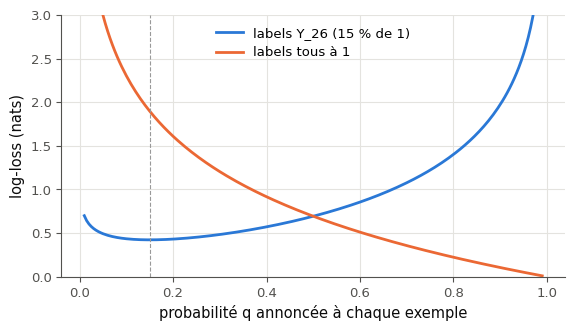

In [34]:
def constant_log_loss(labels, q):
    """The log-loss (in nats) of the model that gives the same probability q of label 1 to every example."""
    labels = np.asarray(labels, dtype=float)
    return float(-np.mean(labels * np.log(q) + (1 - labels) * np.log(1 - q)))


print(f"a) toujours 0,5 sur Y_26 : {constant_log_loss(Y_26, 0.5):.4f}".replace(".", ","))
print(f"b) toujours 0,15 sur Y_26 : {constant_log_loss(Y_26, 0.15):.4f}".replace(".", ","))
print(f"c) toujours 0,5 sur des labels tous à 1 : {constant_log_loss(ONES_26, 0.5):.4f}".replace(".", ","))
print("d) " + " ; ".join(f"toujours {q} : {constant_log_loss(Y_26, q):.4f}" for q in (0.05, 0.15, 0.35, 0.5)).replace(".", ","))
qs = np.linspace(0.01, 0.99, 197)
fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.plot(qs, [constant_log_loss(Y_26, q) for q in qs], label="labels Y_26 (15 % de 1)")
ax.plot(qs, [constant_log_loss(ONES_26, q) for q in qs], label="labels tous à 1")
ax.axvline(0.15, color="0.6", lw=0.8, ls="--")
ax.set_xlabel("probabilité q annoncée à chaque exemple")
ax.set_ylabel("log-loss (nats)")
ax.set_ylim(0, 3)
ax.legend()
plt.show()

**Après l'expérience**, dans ta copie : pourquoi a) et c) sont-elles égales, et pourquoi la log-loss du modèle 0,5 ne dépend-elle pas des labels ? Que vaut b) en termes d'entropie (fiche §2) ? Pourquoi aucun modèle constant ne fait-il mieux que b) sur `Y_26`, et que doit donc battre un modèle qui regarde les features ? Sur les labels tous à 1, pourquoi la courbe n'a-t-elle pas de minimum dans $]0, 1[$ ?

💡 a) et c) : chaque exemple coûte $-\ln 0{,}5 = \ln 2 \approx 0{,}693$, quel que soit son label : la log-loss du modèle 0,5 ne dépend pas des labels. b) $-0{,}15\ln 0{,}15 - 0{,}85\ln 0{,}85 \approx 0{,}4227$ : c'est l'entropie, en nats, de la fréquence 0,15. d) La log-loss d'un modèle constant est $-\frac{1}{n}$ fois la log-vraisemblance de Bernoulli des labels en $q$ : elle est la plus petite au maximum de vraisemblance, la fréquence des 1 (fiche §1 et §2) ; 0,05 et 0,35 donnent $\approx 0{,}4930$ et $0{,}5236$. Un modèle qui regarde les features doit faire mieux que 0,4227, pas seulement mieux que $\ln 2$. Sur des labels tous à 1, la log-loss $-\ln q$ décroît jusqu'à $q = 1$ : le maximum de vraisemblance $\hat{p} = 1$ est au bord.

### Ex M13a.27 — La variabilité du maximum de vraisemblance d'une loi de Bernoulli d'un échantillon à l'autre 🔬 ★★ ⏱️ 20 min
**Objectif :** mesurer de combien l'estimation $\hat{p}$ varie d'un échantillon à l'autre, comparer à la formule $\sqrt{p(1 - p)/n}$, et voir l'effet de la taille de l'échantillon.  
**Prérequis :** fiche §1 ; M02c · **Parcours :** C

Une loi de Bernoulli de paramètre $p = 0{,}3$ (connu ici, puisque c'est toi qui tires les données). Pour chaque taille $n$ de `SIZES_27`, tire 2 000 échantillons de $n$ labels, calcule le maximum de vraisemblance $\hat{p}$ de chacun (la proportion de 1), et regarde comment ces 2 000 valeurs se dispersent. Écris :
- `phat_samples(rng, n)` : les 2 000 valeurs de $\hat{p}$ pour des échantillons de taille $n$, en tirant les labels par `rng.random((N_SAMPLES_27, n)) < P_27` (un échantillon par ligne), puis en prenant la moyenne de chaque ligne ;
- `spread_table(seed=4127)` : le dictionnaire `{n: les 2 000 valeurs de p̂}` pour $n$ = 25, 100 et 400, **dans cet ordre**, avec **un seul** générateur `np.random.default_rng(seed)`, créé une fois (c'est ce qui rend tes nombres égaux à ceux de la vérification).

Puis calcule :
- a) les écarts-types des 2 000 valeurs de $\hat{p}$ pour $n$ = 25, 100 et 400, avec `np.std(..., ddof=1)` (une liste, 5 décimales) ;
- b) leurs valeurs théoriques $\sqrt{p(1 - p)/n}$ (une liste, 5 décimales) ;
- c) vrai ou faux : chaque écart-type mesuré est à moins de 5 % de sa valeur théorique ;
- d) les deux rapports des écarts-types mesurés, $n = 25$ sur $n = 100$ puis $n = 100$ sur $n = 400$ (une liste, 2 décimales) ;
- e) l'entier par lequel l'écart-type théorique est divisé quand $n$ est multiplié par 4.

Une cellule trace ensuite les trois histogrammes, avec la densité de la loi normale $\mathcal{N}\big(p, \frac{p(1 - p)}{n}\big)$.

Dans ta copie : d'où vient $\sqrt{p(1 - p)/n}$ (M02c : la variance d'une moyenne de $n$ variables indépendantes) ? Combien de labels faudrait-il pour que l'écart-type de $\hat{p}$ tombe sous 0,01 ? Pourquoi les histogrammes ressemblent-ils à des cloches de plus en plus étroites, et quel lien avec la figure de la fiche §1 (une log-vraisemblance plus creuse quand $n$ grandit) ? Que dire d'une proportion estimée sur 25 exemples à « 0,32 » ?

In [35]:
P_27 = 0.3                    # the true parameter of the Bernoulli law
SIZES_27 = (25, 100, 400)     # the sizes n of the samples
N_SAMPLES_27 = 2000           # the number of samples for each n

[0.09272, 0.04606, 0.02373] [0.09165, 0.04583, 0.02291] True [2.01, 1.94] 2
moyennes des p̂ : [0.2987, 0.3006, 0.2994]  ; n pour un écart-type de 0,01 : 2100


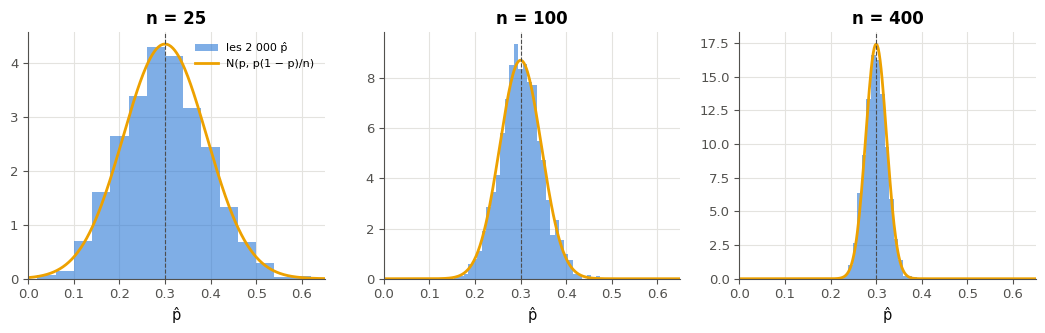

In [36]:
def phat_samples(rng, n):
    """The N_SAMPLES_27 maximum likelihood estimates p̂ of samples of n labels of a Bernoulli law of parameter P_27:
    the labels drawn as rng.random((N_SAMPLES_27, n)) < P_27 (one sample per row), then the mean of each row."""
    labels = rng.random((N_SAMPLES_27, n)) < P_27
    return labels.mean(axis=1)


def spread_table(seed=4127):
    """{n: the array of the N_SAMPLES_27 values of p̂} for n in SIZES_27, in this order, with ONE generator
    np.random.default_rng(seed), created once."""
    rng = np.random.default_rng(seed)
    return {n: phat_samples(rng, n) for n in SIZES_27}


table_27 = spread_table()
measured_27 = [float(np.std(table_27[n], ddof=1)) for n in SIZES_27]
theory_27 = [math.sqrt(P_27 * (1 - P_27) / n) for n in SIZES_27]
answer_M13a_27a = [round(s, 5) for s in measured_27]
answer_M13a_27b = [round(s, 5) for s in theory_27]
answer_M13a_27c = all(abs(m - t) / t < 0.05 for m, t in zip(measured_27, theory_27))
answer_M13a_27d = [round(measured_27[0] / measured_27[1], 2), round(measured_27[1] / measured_27[2], 2)]
answer_M13a_27e = 2
print(answer_M13a_27a, answer_M13a_27b, answer_M13a_27c, answer_M13a_27d, answer_M13a_27e)
print("moyennes des p̂ :", [round(float(np.mean(table_27[n])), 4) for n in SIZES_27],
      " ; n pour un écart-type de 0,01 :", math.ceil(P_27 * (1 - P_27) / 0.01 ** 2))
table_fig_27 = spread_table()
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
try:
    grid_27 = np.linspace(0.0, 0.65, 300)
    for ax, n in zip(axes, SIZES_27):
        sd = math.sqrt(P_27 * (1 - P_27) / n)
        ax.hist(table_fig_27[n], bins=np.arange(-0.5, n + 1.5, max(1, n // 100)) / n, density=True, alpha=0.6,
                label="les 2 000 p̂")
        ax.plot(grid_27, np.exp(-(grid_27 - P_27) ** 2 / (2 * sd ** 2)) / (sd * math.sqrt(2 * math.pi)), color="C3",
                label="N(p, p(1 − p)/n)")
        ax.axvline(P_27, color="0.3", lw=0.8, ls="--")
        ax.set_xlim(0.0, 0.65)
        ax.set_title(f"n = {n}")
        ax.set_xlabel("p̂")
    axes[0].legend(fontsize=8)
except BaseException:
    plt.close(fig)
    raise
plt.show()

In [37]:
rng_27r = np.random.default_rng(4127)
samples_27r = [(rng_27r.random((2000, n)) < 0.3).mean(axis=1) for n in (25, 100, 400)]
std_27r = [float(np.std(s, ddof=1)) for s in samples_27r]
fresh_27r = [float(np.std((np.random.default_rng(4127).random((2000, n)) < 0.3).mean(axis=1), ddof=1))
             for n in (25, 100, 400)]                     # a new generator for each n
transposed_27r = [float(np.std((r.random((n, 2000)) < 0.3).mean(axis=0), ddof=1))
                  for r in [np.random.default_rng(4127)] for n in (25, 100, 400)]   # one sample per column
FRESH_27 = "un seul générateur, créé une fois dans spread_table, puis passé à phat_samples pour 25, 100 et 400"
TRANSPOSED_27 = "un échantillon par LIGNE : rng.random((N_SAMPLES_27, n)), puis la moyenne de chaque ligne (axis=1)"
wbm.record("M13a.27a", std_27r, decimals=5,
           mistakes={"l'écart-type, pas la variance : np.std, ou la racine de np.var": [s ** 2 for s in std_27r],
                     "l'énoncé demande l'écart-type d'échantillon, ddof=1": [float(np.std(s)) for s in samples_27r],
                     FRESH_27: fresh_27r, TRANSPOSED_27: transposed_27r})
wbm.record("M13a.27b", [math.sqrt(0.21 / n) for n in (25, 100, 400)], decimals=5,
           mistakes={"l'écart-type théorique est la RACINE de p(1 − p)/n": [0.21 / n for n in (25, 100, 400)]})
wbm.record("M13a.27c", True,
           mistakes={"compare chaque écart-type mesuré à SA valeur théorique : |mesuré − théorique| / théorique": False})
wbm.record("M13a.27d", [std_27r[0] / std_27r[1], std_27r[1] / std_27r[2]], decimals=2,
           mistakes={"le plus petit n d'abord : l'écart-type pour n divisé par celui pour 4n":
                         [std_27r[1] / std_27r[0], std_27r[2] / std_27r[1]],
                     FRESH_27: [fresh_27r[0] / fresh_27r[1], fresh_27r[1] / fresh_27r[2]],
                     TRANSPOSED_27: [transposed_27r[0] / transposed_27r[1], transposed_27r[1] / transposed_27r[2]]})
wbm.record("M13a.27e", 2,
           mistakes={"l'écart-type varie comme 1/√n : multiplier n par 4 le divise par √4": 4})

WBM_ANSWER {"decimals": 5, "element_coarse": [["ddc96996afad4139b230412e4ba1425c51e40ef7a8c39771f88c45b6e138deb2"], ["a19f93d244437279da327063b65f9af7dee7e356035cb297ab12320e1e9a1874"], ["8b07ed4cf53a5dca9db2887815c9cbce44a1c3824966266678a33e40318d6df6"]], "element_coarse_any": [["74ec987dbb8bc8ace1840efedb28e7c2ed480138e4624d884a2195dc74c354a9", "e7dcc9b70e4f787617b485a5534fd679498cc268db5b4378887c48337ea25789", "59d463dd355f54e7b85fa5bca5123f6fe7e33e58628ff9bf596de7267fb1f96a"], ["30e52c13ae04eb18ce79c988644a140ead2a486ceb243c5ccd20f547f3357d57", "a4770eed97d778a7422a786b4c99dc03732c5a508f706d4566e29522d486a5ef"], ["fbc6862bc658b77d08422539b038768eab4e5bf8f328737984aec58e77dbc1d2", "673fc0a39c7b10148ebb66c23996cb067d928a96085db0e7c3b5cd88e9b9ca63"]], "element_hashes": ["c72c12f1c86b8b266aed3d50286cba97e3e3b8c8912d0ca89246e5deac869e8f", "faf834bc72377ed1e93f9e1ebbffb05c4041f5b03ef2fddde9eca664f930e73d", "b3d987197954b6ee9591ab0aa0f48fb6b5d42105ec6563f90f5edf2b4acb735e"], "hash": "e2df

💡 Mesurés : $\approx 0{,}0927$, $0{,}0461$ et $0{,}0237$, pour $\sqrt{0{,}21/n} \approx 0{,}0917$, $0{,}0458$ et $0{,}0229$ (écarts relatifs de 1 %, 0,5 % et 3,6 %, du même ordre que l'incertitude d'un écart-type estimé sur 2 000 valeurs, environ $1/\sqrt{2 \times 2\,000} \approx 1{,}6\,\%$). $\hat{p}$ est la moyenne de $n$ variables de Bernoulli indépendantes, de variance $p(1 - p)$ : sa variance est $\frac{p(1 - p)}{n}$ (M02c), et son écart-type est divisé par $\sqrt{4} = 2$ quand $n$ est multiplié par 4 (rapports mesurés 2,01 et 1,94). Pour un écart-type sous 0,01, il faut $n \ge 0{,}21/10^{-4} = 2\,100$ labels. Sur 25 exemples, « 0,32 » a une incertitude de l'ordre de $\pm 0{,}09$ : le deuxième chiffre ne veut rien dire.

### Ex M13a.28 — L'entropie et l'indice de Gini sur les lois à trois issues : lignes de niveau et maximum au centre 🎨 ★ ⏱️ 25 min
**Objectif :** dessiner l'entropie et l'indice de Gini sur le triangle des lois à trois issues, et voir où et comment ils sont maximaux.  
**Prérequis :** fiche §6 · **Parcours :** C, E

Une loi à trois issues $(p_1, p_2, p_3)$, positive et de somme 1, est un point d'un triangle : chaque sommet est une loi certaine, le milieu d'un côté une loi qui partage sa masse entre deux issues, le centre la loi uniforme. La cellule fournie donne `simplex_grid()`, une grille de lois (une par ligne, de coordonnées multiples de $\frac{1}{60}$), et `to_plane(P)`, qui place chaque loi dans le triangle. Écris :
- `entropy_bits(P)` : l'entropie en bits de chaque loi (une par ligne), $-\sum_k p_k\log_2 p_k$, où un terme $0 \log_2 0$ compte pour 0 **sans** calculer $\log_2 0$ (aucun avertissement) ;
- `gini(P)` : l'indice de Gini $1 - \sum_k p_k^2$ de chaque loi ;
- `draw_impurities(axes)` : dans les deux axes reçus (sans en ouvrir d'autres), le triangle et les lignes de niveau de l'entropie (à gauche) et de l'indice de Gini (à droite) sur `simplex_grid()`, avec `ax.tricontourf` ou `ax.tricontour` sur les points de `to_plane`, et une marque à la loi où chacun est le plus grand. Mets `ax.set_aspect("equal")` et un titre par axe.

La cellule de vérification contrôle tes valeurs sur cinq lois (comparées à `scipy.stats.entropy`), la symétrie des deux impuretés quand on permute les issues, la position de leur maximum, leur concavité sur 200 couples de lois, puis trace ta figure.

Dans ta copie : où est le maximum de chaque impureté, et pour quelle loi ? Pourquoi les lignes de niveau de Gini sont-elles des cercles centrés au centre du triangle (développe $\lVert \mathbf{p} - \mathbf{u} \rVert^2$, avec $\mathbf{u}$ la loi uniforme) ? Celles de l'entropie en sont-elles ? Sur un côté du triangle, une issue a la probabilité 0 : quelle fonction d'une seule variable retrouves-tu ? Près d'un sommet, quelle impureté monte le plus vite, et pourquoi (regarde la pente de $-p\log_2 p$ en 0) ?

In [38]:
def simplex_grid(n=60):
    """The laws (p1, p2, p3) whose coordinates are multiples of 1/n, one law per row."""
    i, j = np.meshgrid(np.arange(n + 1), np.arange(n + 1), indexing="ij")
    keep = i + j <= n
    return np.column_stack([i[keep], j[keep], n - i[keep] - j[keep]]) / n


def to_plane(P):
    """The points of the plane of the laws P (one per row): the laws (1, 0, 0), (0, 1, 0) and (0, 0, 1) go to the
    vertices (0, 0), (1, 0) and (1/2, √3/2) of an equilateral triangle."""
    P = np.asarray(P, dtype=float)
    return P[:, 1] + P[:, 2] / 2, P[:, 2] * math.sqrt(3) / 2

✅ entropy_bits : une entropie par loi, en bits, 0 log₂ 0 compris, sans avertissement
✅ gini : un indice de Gini par loi
✅ les impuretés ne dépendent pas de l'ordre des issues : leurs lignes de niveau ont les symétries du triangle
✅ le maximum est au centre du triangle, la loi uniforme
✅ concaves : l'impureté d'un mélange de deux lois est au moins la moyenne de leurs impuretés


✅ draw_impurities dessine dans les deux axes reçus


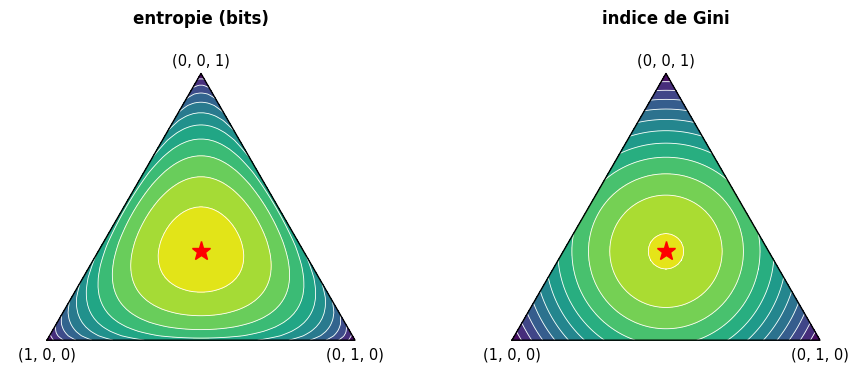

✅ Ex M13a.28 : les impuretés et leur figure sont justes.


In [39]:
def entropy_bits(P):
    """The entropies in bits of the laws P (one per row), where a term 0 log₂ 0 counts as 0: an array."""
    P = np.asarray(P, dtype=float)
    logs = np.log2(np.where(P > 0, P, 1.0))          # log₂ 1 = 0 where p = 0: the term 0 log₂ 0 counts as 0
    return -np.sum(P * logs, axis=1)


def gini(P):
    """The Gini indices 1 − Σ p_k² of the laws P (one per row): an array."""
    P = np.asarray(P, dtype=float)
    return 1 - np.sum(P ** 2, axis=1)


def draw_impurities(axes):
    """In the two axes received (and no other): the triangle of the laws with three outcomes, the level lines of the
    entropy (left) and of the Gini index (right) on simplex_grid(), and a marker at the law where each is largest."""
    grid = simplex_grid()
    xs, ys = to_plane(grid)
    cx, cy = to_plane(np.eye(3))
    for ax, values, title in zip(axes, (entropy_bits(grid), gini(grid)), ("entropie (bits)", "indice de Gini")):
        ax.tricontourf(xs, ys, values, levels=12, cmap="viridis")
        ax.tricontour(xs, ys, values, levels=12, colors="white", linewidths=0.6)
        ax.plot(np.append(cx, cx[0]), np.append(cy, cy[0]), color="black", lw=1)
        best = int(np.argmax(values))
        ax.plot(xs[best], ys[best], marker="*", color="red", markersize=14)
        for x, y, label in zip(cx, cy, ("(1, 0, 0)", "(0, 1, 0)", "(0, 0, 1)")):
            ax.annotate(label, (x, y), textcoords="offset points", xytext=(0, -14 if y == 0 else 6), ha="center")
        ax.set_xlim(-0.12, 1.12)
        ax.set_ylim(-0.1, 1.0)
        ax.set_aspect("equal")
        ax.axis("off")
        ax.set_title(title)


with checked("M13a.28"):
    from scipy.stats import entropy as scipy_entropy

    LAWS_28 = np.array([[0.6, 0.3, 0.1], [0.0, 0.75, 0.25], [1.0, 0.0, 0.0], [0.2, 0.2, 0.6], [0.45, 0.1, 0.45]])
    GRID_28 = simplex_grid()
    results_28 = []

    def report_28(ok, success, failure):
        results_28.append(bool(ok))
        print(("✅ " + success) if ok else ("❌ " + failure))

    with warnings.catch_warnings(record=True) as caught_h:
        warnings.simplefilter("always")
        h_laws, h_grid = np.asarray(entropy_bits(LAWS_28), dtype=float), np.asarray(entropy_bits(GRID_28), dtype=float)
    with warnings.catch_warnings(record=True) as caught_g:
        warnings.simplefilter("always")
        g_laws, g_grid = np.asarray(gini(LAWS_28), dtype=float), np.asarray(gini(GRID_28), dtype=float)
    h_ok_28 = bool(h_laws.shape == (5,) and np.allclose(h_laws, scipy_entropy(LAWS_28.T, base=2), rtol=0, atol=1e-12)
                   and h_grid.shape == (len(GRID_28),) and not caught_h)
    g_ok_28 = bool(g_laws.shape == (5,) and np.allclose(g_laws, 1 - np.sum(LAWS_28 ** 2, axis=1), rtol=0, atol=1e-12)
                   and g_grid.shape == (len(GRID_28),) and not caught_g)
    report_28(h_ok_28, "entropy_bits : une entropie par loi, en bits, 0 log₂ 0 compris, sans avertissement",
              "entropy_bits : une entropie par LIGNE, en bits (log₂), où un terme 0 log₂ 0 compte pour 0 sans calculer "
              "log₂ 0 (np.where ou un masque), sans avertissement")
    report_28(g_ok_28, "gini : un indice de Gini par loi", "gini : 1 − la somme des carrés, une valeur par LIGNE")
    right_28 = [(f, values) for f, values, ok in ((entropy_bits, h_grid, h_ok_28), (gini, g_grid, g_ok_28)) if ok]
    if len(right_28) < 2:                            # the properties below are checked on right values only
        results_28.append(False)
        print("ℹ️ la symétrie, le maximum et la concavité se vérifient une fois les valeurs des deux impuretés justes")
    if right_28:
        swaps_28 = [[1, 2, 0], [1, 0, 2]]            # a rotation and a reflection of the triangle
        report_28(all(np.allclose(np.asarray(f(GRID_28[:, s]), dtype=float), values, rtol=0, atol=1e-12)
                      for f, values in right_28 for s in swaps_28),
                  "les impuretés ne dépendent pas de l'ordre des issues : leurs lignes de niveau ont les symétries du "
                  "triangle",
                  "une impureté change quand on permute les issues : elle doit traiter les trois de la même façon")
        center_28 = np.full(3, 1 / 3)
        report_28(all(np.allclose(GRID_28[np.argmax(values)], center_28) for _, values in right_28),
                  "le maximum est au centre du triangle, la loi uniforme",
                  "le maximum de tes impuretés n'est pas au centre du triangle : relis tes formules")
        pairs_28 = np.random.default_rng(4128).dirichlet(np.ones(3), size=(200, 2))
        middle_28 = pairs_28.mean(axis=1)
        report_28(all(np.all(np.asarray(f(middle_28), dtype=float)
                             >= (np.asarray(f(pairs_28[:, 0]), dtype=float) + np.asarray(f(pairs_28[:, 1]), dtype=float)) / 2
                             - 1e-12) for f, _ in right_28),
                  "concaves : l'impureté d'un mélange de deux lois est au moins la moyenne de leurs impuretés",
                  "une de tes impuretés n'est pas concave sur 200 couples de lois : relis tes formules")
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
    try:
        opened_28 = drawn(draw_impurities, axes)
    except BaseException:
        plt.close(fig)
        raise
    report_28(not opened_28 and all(ax.collections or ax.lines for ax in axes),
              "draw_impurities dessine dans les deux axes reçus",
              "draw_impurities doit dessiner dans les deux axes reçus, sans ouvrir de figure (ni plt.figure ni "
              "plt.subplots)")
    plt.show()
    verdict("M13a.28", all(results_28), "les impuretés et leur figure sont justes.",
            "relis les lignes ❌ ci-dessus.")

💡 Les deux impuretés sont maximales au centre, la loi uniforme $(\frac{1}{3}, \frac{1}{3}, \frac{1}{3})$, et nulles aux sommets. Avec $\mathbf{u}$ la loi uniforme, $\lVert \mathbf{p} - \mathbf{u} \rVert^2 = \sum_k p_k^2 - \frac{2}{3}\sum_k p_k + \frac{1}{3} = \sum_k p_k^2 - \frac{1}{3}$ : l'indice de Gini ne dépend que de la distance au centre, ses lignes de niveau sont des cercles (coupés par les côtés). Celles de l'entropie n'en sont pas : elles s'arrondissent près du centre et s'aplatissent le long des côtés. Sur un côté, on retrouve l'entropie et le Gini d'une loi à deux issues. Près d'un sommet, l'entropie monte bien plus vite : la pente de $-p\log_2 p$ est infinie en $p = 0$, celle de $p(1 - p)$ vaut 1 ; c'est pourquoi l'entropie « voit » mieux les classes rares.

## Partie C · Erreurs classiques, savoir-faire et défi

Fiche §1 à §3. Quatre erreurs à trouver dans un résumé de modèle, deux maxima de vraisemblance vérifiés avec SymPy, puis un maximum de vraisemblance sans formule.

### Ex M13a.29 — Chasse à l'erreur : un ln 0, une sigmoïde qui déborde, une variance de maximum de vraisemblance divisée par n − 1 🐛 ★ ⏱️ 15 min
**Objectif :** repérer dans un code de résumé d'un modèle les erreurs classiques de la vraisemblance et des scores, puis calculer les bonnes valeurs.  
**Prérequis :** fiche §1 à §3 · **Parcours :** C

Un collègue résume les sorties de deux modèles et un échantillon (la cellule fournie) : les probabilités `P_29` (arrondies : certaines valent exactement 0 ou 1), les scores `Z_29` (dont deux immenses) et des mesures `X_29`. Sept lignes portent une lettre et un commentaire qui dit ce qu'elles doivent calculer. Quatre lignes ne font pas ce que dit leur commentaire. **Sans exécuter son code**, trouve-les.

```python
y, p, z, x = Y_29, P_29, Z_29, X_29
ll = np.sum(y * np.log(p) + (1 - y) * np.log(1 - p))       # (A) the log-likelihood of the labels y under p
prob = 1 / (1 + np.exp(-z))                                 # (B) σ(z), without any warning, even for z = −900
loss = np.mean(np.log(1 + np.exp(z)) - y * z)               # (C) the mean logistic loss of the scores z
p_hat = np.mean(y)                                          # (D) the maximum likelihood estimate of P(Y = 1)
base = -(p_hat * np.log(p_hat) + (1 - p_hat) * np.log(1 - p_hat))   # (E) the log-loss of the constant model p̂
mu = np.mean(x)                                             # (F) the maximum likelihood estimate of μ
var = np.var(x, ddof=1)                                     # (G) the maximum likelihood estimate of σ²
```

Questions :
- a) les lettres des lignes fausses, dans l'ordre alphabétique (un texte) ;
- b) la bonne valeur de `ll` (4 décimales) ;
- c) la bonne valeur de `loss` (4 décimales) ;
- d) la bonne valeur de `var` (4 décimales).

Pour b) à d), écris le code corrigé dans la cellule (c'est permis : seule la recherche des lignes fausses se fait sans exécuter).

In [40]:
Y_29 = np.array([1, 0, 0, 1, 1, 0, 0, 1, 0, 0, 1, 0])                                  # 12 labels
P_29 = np.array([0.9, 0.0, 0.25, 1.0, 0.7, 0.4, 0.05, 0.55, 0.0, 0.3, 0.85, 0.15])           # a model's P(Y = 1), rounded
Z_29 = np.array([2.1, -900.0, -1.3, 900.0, 0.8, -0.2, -3.1, 0.3, -5.0, -0.9, 1.7, -2.4])    # another model's scores
X_29 = np.round(np.random.default_rng(4129).normal(5.0, 2.0, size=12), 2)                   # 12 measures

In [41]:
answer_M13a_29a = "ABCG"
y_29, p_29, z_29, x_29 = Y_29, P_29, Z_29, X_29
ll_29 = float(np.sum(np.log(np.where(y_29 == 1, p_29, 1 - p_29))))   # (A) the probability of the OBSERVED label only
e_29 = np.exp(-np.abs(z_29))                                         # (B) at most 1: no overflow
prob_29 = np.where(z_29 >= 0, 1 / (1 + e_29), e_29 / (1 + e_29))
loss_29 = float(np.mean(np.maximum(z_29, 0) + np.log1p(e_29) - y_29 * z_29))   # (C) the stable softplus
var_29 = float(np.var(x_29))                                         # (G) the maximum likelihood divides by n
answer_M13a_29b, answer_M13a_29c, answer_M13a_29d = round(ll_29, 4), round(loss_29, 4), round(var_29, 4)
print(answer_M13a_29a, answer_M13a_29b, answer_M13a_29c, answer_M13a_29d)
with warnings.catch_warnings(record=True) as caught_29:               # what the colleague's lines give
    warnings.simplefilter("always")
    wrong_29 = (np.sum(y_29 * np.log(p_29) + (1 - y_29) * np.log(1 - p_29)), (1 / (1 + np.exp(-z_29)))[1],
                np.mean(np.log(1 + np.exp(z_29)) - y_29 * z_29), np.var(x_29, ddof=1))
print("lignes du collègue : (A)", wrong_29[0], " (B) σ(−900) =", wrong_29[1], " (C)", wrong_29[2],
      " (G)", round(float(wrong_29[3]), 4))
print("avertissements :", sorted({str(w.message) for w in caught_29}))

ABCG -2.5914 0.2106 3.8753
lignes du collègue : (A) nan  (B) σ(−900) = 0.0  (C) inf  (G) 4.2276
avertissements : ['divide by zero encountered in log', 'invalid value encountered in multiply', 'overflow encountered in exp']


In [42]:
wbm.record("M13a.29a", "ABCG",
           mistakes={"il manque une ligne fautive : regarde ce que vaut chaque terme quand une probabilité vaut exactement 0 ou 1": "BCG",
                     "il manque une ligne fautive : regarde ce que calcule NumPy pour chaque valeur de z, les plus négatives surtout": "ACG",
                     "il manque une ligne fautive : regarde ce que devient e^z en flottants pour les plus grandes valeurs de z": "ABG",
                     "il manque une ligne fautive : regarde les conventions de NumPy, et la formule du maximum de vraisemblance d'une variance": "ABC",
                     "une ligne de trop : une des lignes que tu cites est correcte ; refais le calcul de chacune sur un petit exemple": {"ABCDG", "ABCEG", "ABCFG"},
                     "une des lignes que tu cites est correcte, et il manque une ligne fautive : regarde ce que vaut chaque terme quand une probabilité vaut exactement 0 ou 1": {"BCDG", "BCEG", "BCFG"},
                     "une des lignes que tu cites est correcte, et il manque une ligne fautive : regarde ce que calcule NumPy pour chaque valeur de z, les plus négatives surtout": {"ACDG", "ACEG", "ACFG"},
                     "une des lignes que tu cites est correcte, et il manque une ligne fautive : regarde ce que devient e^z en flottants pour les plus grandes valeurs de z": {"ABDG", "ABEG", "ABFG"},
                     "une des lignes que tu cites est correcte, et il manque une ligne fautive : regarde les conventions de NumPy, et la formule du maximum de vraisemblance d'une variance": {"ABCD", "ABCE", "ABCF"},
                     "plusieurs lignes fautives manquent : reprends chaque ligne avec un petit exemple": {"A", "B", "C", "G", "AB", "AC", "AG", "BC", "BG", "CG"},
                     "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple": {"D", "E", "F", "AD", "AE", "AF", "BD", "BE", "BF", "CD", "CE", "CF", "DE", "DF", "DG", "EF", "EG", "FG", "ABD", "ABE", "ABF", "ACD", "ACE", "ACF", "ADE", "ADF", "ADG", "AEF", "AEG", "AFG", "BCD", "BCE", "BCF", "BDE", "BDF", "BDG", "BEF", "BEG", "BFG", "CDE", "CDF", "CDG", "CEF", "CEG", "CFG", "DEF", "DEG", "DFG", "EFG", "ABDE", "ABDF", "ABEF", "ACDE", "ACDF", "ACEF", "ADEF", "ADEG", "ADFG", "AEFG", "BCDE", "BCDF", "BCEF", "BDEF", "BDEG", "BDFG", "BEFG", "CDEF", "CDEG", "CDFG", "CEFG", "DEFG", "ABCDE", "ABCDF", "ABCEF", "ABDEF", "ABDEG", "ABDFG", "ABEFG", "ACDEF", "ACDEG", "ACDFG", "ACEFG", "ADEFG", "BCDEF", "BCDEG", "BCDFG", "BCEFG", "BDEFG", "CDEFG", "ABCDEF", "ABDEFG", "ACDEFG", "BCDEFG"},
                     "plusieurs lignes que tu cites sont correctes : vérifie chacune avec un petit exemple": {"ABCDEG", "ABCDFG", "ABCEFG", "ABCDEFG"}})
Y_29r = np.array([1, 0, 0, 1, 1, 0, 0, 1, 0, 0, 1, 0])
P_29r = np.array([0.9, 0.0, 0.25, 1.0, 0.7, 0.4, 0.05, 0.55, 0.0, 0.3, 0.85, 0.15])
Z_29r = np.array([2.1, -900.0, -1.3, 900.0, 0.8, -0.2, -3.1, 0.3, -5.0, -0.9, 1.7, -2.4])
X_29r = np.round(np.random.default_rng(4129).normal(5.0, 2.0, size=12), 2)
ll_29r = float(np.sum(np.log(np.where(Y_29r == 1, P_29r, 1 - P_29r))))
loss_29r = float(np.mean(np.logaddexp(0, Z_29r) - Y_29r * Z_29r))
wbm.record("M13a.29b", ll_29r, decimals=4,
           mistakes={"(A) calcule une log-vraisemblance : une SOMME sur les labels, pas une moyenne": ll_29r / 12})
wbm.record("M13a.29c", loss_29r, decimals=4,
           mistakes={"e^900 déborde : écris la softplus max(z, 0) + ln(1 + e^(−|z|))": math.inf,
                     "la log-loss est une MOYENNE sur les exemples : divise la somme par leur nombre": loss_29r * 12})
wbm.record("M13a.29d", float(np.var(X_29r)), decimals=4,
           mistakes={"le maximum de vraisemblance d'une variance divise par n, pas par n − 1": float(np.var(X_29r, ddof=1)),
                     "la question demande la variance, pas l'écart-type": float(np.std(X_29r))})

WBM_ANSWER {"hash": "7c9c10b93018adf4fbc65f459753ff2458b625d1ae69812f2ad92c7b517880f7", "id": "M13a.29a", "kind": "str", "mistakes": {"0284f15b689b15de276c8a8a216b51be6db3e47070e76c812f8af5de95ac711b": "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple", "067ea5ba89ef95731587e1e01f4ffdf4070bc8db39c32c0185d9f8d2c7a4953b": "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple", "0bbe26113f8fe73c9a81dee24186ed6cbff23e3cc5d795ffb7ec18f6c8cf5f39": "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple", "104e59bcd849af25f6dfe36b1b265394071e76b5fec2dda08b0fe0b74e38798d": "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple", "158a04c3c7d3c822cb2b7233643a77402412b7c20c298087146046c2b953e650": "une des lignes que tu cites est corre

**Après la vérification**, dans ta copie : pour chaque ligne fausse, que se passe-t-il exactement (une valeur, `nan`, `inf`, un avertissement), et comment la corriger ? Laquelle donne une valeur juste mais avec un avertissement ? Laquelle donne un nombre faux sans aucun signal ? Pourquoi la ligne (E), qui ressemble à (A), est-elle juste ici ?

💡 (A) Quand $p_i = 0$ pour un label 0, ou $p_i = 1$ pour un label 1, la formule calcule $0 \times \ln 0 = 0 \times (-\infty)$ : `nan`, qui contamine la somme (et deux avertissements) ; il faut ne prendre le $\ln$ que de la probabilité du label observé (`np.where`), ou `scipy.special.xlogy`. (B) Pour $z = -900$, $e^{900}$ déborde en `inf`, et $1/(1 + \infty) = 0$ : la valeur est juste, mais avec un avertissement d'overflow ; pour $z < 0$, on écrit $\frac{e^{z}}{1 + e^{z}}$. (C) Pour $z = 900$, `np.log(1 + np.exp(z))` vaut `inf`, et la log-loss aussi, alors que le modèle a raison (score 900, label 1) : la softplus stable donne 0,2106. (G) `ddof=1` divise par $n - 1$ : un nombre plausible, faux sans aucun signal, le piège le plus dangereux. (E) est juste parce que $\hat{p} = \frac{5}{12}$ n'est ni 0 ni 1 : un $\hat{p}$ calculé sur des labels n'atteint 0 ou 1 que si tous les labels sont égaux.

### Ex M13a.30 — Vérifier avec SymPy le maximum de vraisemblance d'une loi géométrique et d'une loi de Poisson 🛠️ ★ ⏱️ 15 min
**Objectif :** faire calculer par SymPy une log-vraisemblance, sa dérivée, son point critique et le signe de sa dérivée seconde, pour vérifier un maximum de vraisemblance fait à la main.  
**Prérequis :** fiche §1 ; M05a · **Parcours :** C

Vérifier un calcul à la main avec un logiciel de calcul formel, c'est un geste de métier. La cellule fournie définit les symboles `p` et `lam` (positifs) et deux échantillons :
- `GEOM_30`, cinq observations d'une loi **géométrique** (le rang du premier succès, $P(X = k) = (1 - p)^{k - 1}p$ pour $k \ge 1$) ;
- `POIS_30`, six observations d'une loi de **Poisson** ($P(X = k) = e^{-\lambda}\frac{\lambda^k}{k!}$ pour $k \ge 0$).

Fais d'abord le calcul à la main, dans ta copie : écris $\ell(p)$, dérive, résous $\ell'(p) = 0$ (tu dois trouver $\hat{p} = 1/\bar{x}$), et le signe de $\ell''$ ; de même pour $\lambda$ (tu dois trouver $\hat{\lambda} = \bar{x}$). Puis fais-le faire par SymPy, en définissant :
- `ell_geom` : $\ell(p)$ pour `GEOM_30`, une expression SymPy (une somme de `sympy.log(...)` sur les observations) ;
- `dell_geom` : sa dérivée, par `sympy.diff` ;
- `p_hat` : la solution de $\ell'(p) = 0$, par `sympy.solve` (un nombre SymPy, pas la liste que rend `solve`) ;
- `d2_geom` : $\ell''(\hat{p})$, la dérivée seconde en $\hat{p}$ (`sympy.diff(..., p, 2)`, puis `.subs(p, p_hat)`) ;
- `ell_pois`, `lam_hat` et `d2_pois` : la même chose pour `POIS_30` et $\lambda$ (les termes constants $-\ln x_i!$ peuvent être omis : ils ne changent ni la dérivée ni le maximum).

La cellule de vérification compare chacun de tes objets à un calcul indépendant (en quelques points pour les expressions) et dit ✅ ou ❌.

Dans ta copie : pourquoi le signe de $\ell''(\hat{p})$ suffit-il à conclure à un maximum ici (regarde le signe de $\ell''(p)$ sur tout $]0, 1[$) ? `sympy.solve` a-t-il trouvé d'autres solutions, et pourquoi pas ? Écris $\hat{p}$ et $\hat{\lambda}$ en fonction de $\bar{x}$ : lequel des deux est une moyenne, lequel l'inverse d'une moyenne, et pourquoi est-ce naturel (l'espérance d'une loi géométrique est $\frac{1}{p}$) ?

In [43]:
p = sympy.symbols("p", positive=True)
lam = sympy.symbols("lambda", positive=True)
GEOM_30 = [3, 1, 4, 2, 5]        # observations of a geometric law: P(X = k) = (1 − p)^(k − 1) p, k = 1, 2, ...
POIS_30 = [2, 0, 3, 1, 4, 2]     # observations of a Poisson law: P(X = k) = e^(−λ) λ^k / k!, k = 0, 1, ...

In [44]:
ell_geom = sum(sympy.log((1 - p) ** (k - 1) * p) for k in GEOM_30)
dell_geom = sympy.diff(ell_geom, p)
p_hat = sympy.solve(sympy.Eq(dell_geom, 0), p)[0]
d2_geom = sympy.simplify(sympy.diff(ell_geom, p, 2).subs(p, p_hat))
ell_pois = sum(sympy.log(sympy.exp(-lam) * lam ** x / sympy.factorial(x)) for x in POIS_30)
lam_hat = sympy.solve(sympy.diff(ell_pois, lam), lam)[0]
d2_pois = sympy.simplify(sympy.diff(ell_pois, lam, 2).subs(lam, lam_hat))
print("ℓ′(p) =", sympy.simplify(dell_geom), " ; solutions :", sympy.solve(dell_geom, p), " ; ℓ″(p̂) =", d2_geom)
print("ℓ″(p) =", sympy.simplify(sympy.diff(ell_geom, p, 2)))
print("ℓ′(λ) =", sympy.simplify(sympy.diff(ell_pois, lam)), " ; λ̂ =", lam_hat, " ; ℓ″(λ̂) =", d2_pois)


with checked("M13a.30"):
    def at_30(expr, symbol, point):
        """The value of the SymPy expression expr at symbol = point, as a float (None if not a real number)."""
        try:
            value = complex(sympy.sympify(expr).subs(symbol, point).evalf())
        except (TypeError, ValueError, AttributeError, sympy.SympifyError):
            return None
        return value.real if abs(value.imag) < 1e-12 else None

    def same_30(expr, reference, symbol, points, constant=False):
        """True when expr equals reference at the points (up to an additive constant if constant)."""
        gaps = []
        for point in points:
            a, b = at_30(expr, symbol, point), at_30(reference, symbol, point)
            if a is None or b is None:
                return False
            gaps.append((a - b, max(1.0, abs(b))))
        shift = gaps[0][0] if constant else 0.0
        return all(abs(gap - shift) <= 1e-9 * size for gap, size in gaps)

    def number_30(expr, expected):
        """True when expr is one number equal to expected; else False, or the reason as a text."""
        if isinstance(expr, (list, tuple, set, dict)):
            return "sympy.solve rend une LISTE de solutions : prends-en l'élément, sympy.solve(...)[0]"
        try:
            free = sympy.sympify(expr).free_symbols
            if free:
                return (f"c'est encore une expression de {', '.join(sorted(map(str, free)))} : remplace la variable "
                        f"par la solution, avec .subs(...)")
            return abs(float(sympy.sympify(expr)) - expected) <= 1e-9 * max(1.0, abs(expected))
        except (TypeError, ValueError, AttributeError, sympy.SympifyError):
            return False

    ref_geom_30 = sum((k - 1) * sympy.log(1 - p) + sympy.log(p) for k in GEOM_30)
    ref_pois_30 = sum(x * sympy.log(lam) - lam for x in POIS_30)
    items_30 = [
        ("ell_geom", lambda: ell_geom, lambda e: same_30(e, ref_geom_30, p, [0.2, 0.45, 0.8]),
         "ℓ(p), la log-vraisemblance géométrique : une somme de ln((1 − p)^(kᵢ − 1) p) sur les cinq observations"),
        ("dell_geom", lambda: dell_geom, lambda e: same_30(e, sympy.diff(ref_geom_30, p), p, [0.2, 0.45, 0.8]),
         "ℓ′(p) : sympy.diff(ell_geom, p)"),
        ("p_hat", lambda: p_hat, lambda e: number_30(e, 1 / sum(GEOM_30) * len(GEOM_30)),
         "p̂ : la solution de ℓ′(p) = 0 (sympy.solve), dans ]0, 1["),
        ("d2_geom", lambda: d2_geom,
         lambda e: number_30(e, float(sympy.diff(ref_geom_30, p, 2).subs(p, sympy.Rational(len(GEOM_30), sum(GEOM_30))))),
         "ℓ″(p̂) : la dérivée seconde de ℓ, puis .subs(p, p_hat)"),
        ("ell_pois", lambda: ell_pois, lambda e: same_30(e, ref_pois_30, lam, [0.7, 2.0, 3.5], constant=True),
         "ℓ(λ), la log-vraisemblance de Poisson : une somme de ln(e^(−λ) λ^(xᵢ) / xᵢ!)"),
        ("lam_hat", lambda: lam_hat, lambda e: number_30(e, sum(POIS_30) / len(POIS_30)),
         "λ̂ : la solution de ℓ′(λ) = 0"),
        ("d2_pois", lambda: d2_pois, lambda e: number_30(e, -sum(POIS_30) / (sum(POIS_30) / len(POIS_30)) ** 2),
         "ℓ″(λ̂) : la dérivée seconde de ℓ en λ̂"),
    ]
    done_30, right_30 = 0, 0
    for name, get, test, what in items_30:
        value = get()
        if not filled(value):
            print(f"⏳ {name} : pas encore écrit")
            continue
        done_30 += 1
        result = test(value)
        ok = result is True
        right_30 += ok
        print(f"✅ {name}" if ok else f"❌ {name} : {result if isinstance(result, str) else what}")
    if done_30 < len(items_30):
        print(f"⏳ Ex M13a.30 : {done_30} objets sur {len(items_30)} écrits, dont {right_30} justes.")
    else:
        verdict("M13a.30", right_30 == len(items_30),
                "SymPy confirme les deux maxima de vraisemblance, et le signe de la dérivée seconde dit que ce sont "
                "des maxima.", f"{len(items_30) - right_30} objet(s) faux : relis les lignes ❌ ci-dessus.")

ℓ′(p) = 5*(3*p - 1)/(p*(p - 1))  ; solutions : [1/3]  ; ℓ″(p̂) = -135/2
ℓ″(p) = 5*(-3*p**2 + 2*p - 1)/(p**2*(p**2 - 2*p + 1))
ℓ′(λ) = -6 + 12/lambda  ; λ̂ = 2  ; ℓ″(λ̂) = -3
✅ ell_geom
✅ dell_geom
✅ p_hat
✅ d2_geom
✅ ell_pois
✅ lam_hat
✅ d2_pois
✅ Ex M13a.30 : SymPy confirme les deux maxima de vraisemblance, et le signe de la dérivée seconde dit que ce sont des maxima.


💡 Géométrique : $\ell(p) = \sum_i \big[(k_i - 1)\ln(1 - p) + \ln p\big] = 10\ln(1 - p) + 5\ln p$, $\ell'(p) = \frac{5}{p} - \frac{10}{1 - p}$, nul en $\hat{p} = \frac{5}{15} = \frac{1}{3} = \frac{1}{\bar{x}}$ ($\bar{x} = 3$) ; $\ell''(p) = -\frac{5}{p^2} - \frac{10}{(1 - p)^2} < 0$ sur tout $]0, 1[$ : $\ell$ est concave, le point critique est l'unique maximum, et $\ell''(\hat{p}) = -45 - 22{,}5 = -\frac{135}{2}$. Poisson : $\ell(\lambda) = 12\ln\lambda - 6\lambda - \sum_i \ln x_i!$, $\ell'(\lambda) = \frac{12}{\lambda} - 6$, nul en $\hat{\lambda} = 2 = \bar{x}$, et $\ell''(\hat{\lambda}) = -\frac{12}{4} = -3$. `solve` ne trouve qu'une solution : l'équation se ramène à une équation du premier degré. Le maximum de vraisemblance égale l'espérance du modèle à la moyenne observée : $\frac{1}{p} = \bar{x}$ pour la géométrique, $\lambda = \bar{x}$ pour Poisson.

### Ex M13a.31 — Défi : la proportion d'un mélange de deux lois connues par maximum de vraisemblance, à 1e−6 près du maximum (dichotomie ou Newton) 🏆 ★★★ ⏱️ 25 min
**Objectif :** trouver numériquement un maximum de vraisemblance qui n'a pas de formule, avec une méthode qui garantit sa précision et un budget d'évaluations.  
**Prérequis :** fiche §1 ; M05a ; M10 · **Parcours :** C

Des mesures viennent de deux sources mélangées, de densités **connues** $f_0 = \mathcal{N}(0, 1)$ et $f_1 = \mathcal{N}(2{,}5 ;\ 1)$, dans une proportion $\pi$ **inconnue** : chaque mesure suit la densité $\pi f_1(x) + (1 - \pi) f_0(x)$. Les 400 mesures `X_31` (cellule fournie) donnent la log-vraisemblance et sa dérivée

$$\ell(\pi) = \sum_{i=1}^{400} \ln\big(\pi f_1(x_i) + (1 - \pi) f_0(x_i)\big), \qquad \ell'(\pi) = \sum_{i=1}^{400} \frac{f_1(x_i) - f_0(x_i)}{\pi f_1(x_i) + (1 - \pi) f_0(x_i)},$$

calculées par `ell_31` et `dell_31`. Annuler $\ell'$ ne donne pas de formule : il faut chercher le maximum numériquement. Bonne nouvelle, $\ell$ est **concave** sur $[0, 1]$ (calcule $\ell''$ : une somme de carrés changée de signe), donc $\ell'$ décroît, et un point où elle s'annule est le maximum.

**L'objectif** : écrire `find_weight(ell, dell)`, qui reçoit deux fonctions d'un seul nombre $\pi$ (comme `ell_31` et `dell_31`) et rend le $\hat{\pi} \in [0, 1]$ qui maximise `ell`, à $10^{-6}$ près du vrai maximum, en appelant `ell` et `dell` **au plus 200 fois** en tout. La vérification compte les appels, et essaie ta fonction sur `X_31`, sur un autre échantillon, d'une autre proportion, puis sur deux fonctions concaves dont le maximum est au bord, en 0 et en 1 : ta fonction ne doit utiliser que les deux fonctions reçues (ni `X_31`, ni `ell_31`, ni `make_loglik`). Une grille unique ne suffit pas : $10^{-6}$ près demanderait un million de points. `scipy.optimize` (`minimize`, `brentq`, `fsolve`…), `np.polyfit` et scikit-learn sont interdits. Pense à la **dichotomie** sur $\ell'$ (M05a) ou à la méthode de **Newton** (une dérivée seconde approchée par les valeurs de `dell`), et au cas où le maximum serait au bord, en 0 ou en 1.

Une dernière cellule enregistre si l'objectif est atteint.

Dans ta copie : combien d'évaluations ta méthode a-t-elle utilisées, et combien en faudrait-il, au minimum, pour une précision de $10^{-12}$ ? Pourquoi la concavité garantit-elle que ta méthode ne s'arrête pas sur un faux maximum ? Ton $\hat{\pi}$ est-il égal à la proportion de points venus de $f_1$, et pourquoi pas exactement ?

In [45]:
def normal_pdf(x, mu, sigma):
    """The density of N(mu, sigma²) at x."""
    return np.exp(-(x - mu) ** 2 / (2 * sigma ** 2)) / (sigma * math.sqrt(2 * math.pi))


def mixture_sample(seed, weight, n=400):
    """n points of the mixture weight · N(2.5, 1) + (1 − weight) · N(0, 1)."""
    rng = np.random.default_rng(seed)
    from_f1 = rng.random(n) < weight
    return np.where(from_f1, rng.normal(2.5, 1.0, n), rng.normal(0.0, 1.0, n))


def make_loglik(x):
    """(ell, dell): the log-likelihood ℓ(π) of the mixture π f₁ + (1 − π) f₀ (f₁ = N(2.5, 1), f₀ = N(0, 1)) for the
    sample x, and its derivative ℓ′(π). Both take one number π of [0, 1]."""
    x = np.asarray(x, dtype=float)
    f0, f1 = normal_pdf(x, 0.0, 1.0), normal_pdf(x, 2.5, 1.0)

    def ell(pi):
        return float(np.sum(np.log(pi * f1 + (1 - pi) * f0)))

    def dell(pi):
        return float(np.sum((f1 - f0) / (pi * f1 + (1 - pi) * f0)))

    return ell, dell


X_31 = mixture_sample(4131, 0.35)                # 400 points; you know f₀ and f₁, not the proportion π
ell_31, dell_31 = make_loglik(X_31)
MAX_CALLS_31 = 200

π̂ = 0,335527, ℓ(π̂) = -739,5237


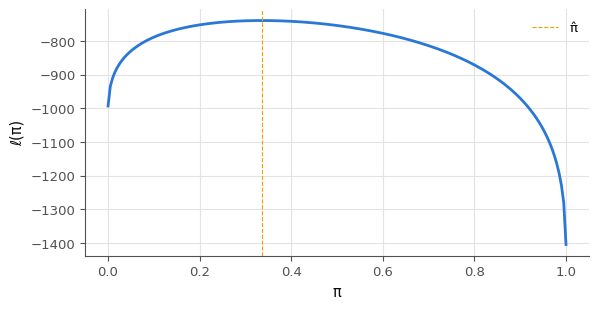

In [46]:
def find_weight(ell, dell):
    """The π in [0, 1] that maximizes ell (a concave function), to 1e-6, with at most MAX_CALLS_31 calls of ell and
    dell together; dell is the derivative of ell. Both take one number π."""
    lo, hi = 0.0, 1.0
    if dell(lo) <= 0:                            # ℓ decreases on [0, 1]: the maximum is at 0
        return lo
    if dell(hi) >= 0:                            # ℓ increases on [0, 1]: the maximum is at 1
        return hi
    while hi - lo > 1e-9:                        # dell decreases: keep the sign change inside [lo, hi]
        mid = (lo + hi) / 2
        if dell(mid) > 0:
            lo = mid
        else:
            hi = mid
    return (lo + hi) / 2


pi_hat_31 = find_weight(ell_31, dell_31)
print(f"π̂ = {pi_hat_31:.6f}, ℓ(π̂) = {ell_31(pi_hat_31):.4f}".replace(".", ","))
pis_31 = np.linspace(0.0, 1.0, 201)
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.plot(pis_31, [ell_31(q) for q in pis_31])
ax.axvline(pi_hat_31, color="C3", lw=0.8, ls="--", label="π̂")
ax.set_xlabel("π")
ax.set_ylabel("ℓ(π)")
ax.legend()
plt.show()

In [47]:
wbm.record("M13a.31", True,
           mistakes={"l'objectif n'est pas atteint : la cellule du défi dit pourquoi": False})

WBM_ANSWER {"hash": "68544967cc4cc02464747fdfc735f8333cebd85d5db67e61603036ad7913bb61", "id": "M13a.31", "kind": "bool", "mistakes": {"8ed56782efe99a692b8eb50a07608273624a1d84b23c368f89fee354fdd50928": "l'objectif n'est pas atteint : la cellule du défi dit pourquoi"}}
📝 Ex M13a.31 : réponse enregistrée (bool).


In [48]:
with checked("M13a.31 défi"):
    import inspect
    import re

    from scipy.optimize import brentq                # the reference maximum (forbidden in find_weight)

    problems_31, ok_31, ran_31 = [], False, False
    try:
        source_31 = inspect.getsource(find_weight)
    except (OSError, TypeError):
        source_31 = ""
    banned_31 = sorted(set(re.findall(r"\b(scipy|optimize|minimize|minimize_scalar|brentq|fsolve|polyfit|sklearn|"
                                      r"X_31|ell_31|dell_31|make_loglik|normal_pdf|mixture_sample)\b", source_31)))
    if banned_31:
        ran_31 = True
        problems_31.append(f"find_weight utilise {', '.join(banned_31)}, interdit dans ce défi")
    cases_31 = [("l'échantillon X_31", *make_loglik(X_31)),
                ("un autre échantillon, d'une autre proportion", *make_loglik(mixture_sample(4132, 0.6))),
                ("une fonction concave de maximum au bord, en 0", lambda t: -(t + 0.3) ** 2, lambda t: -2 * (t + 0.3)),
                ("une fonction concave de maximum au bord, en 1", lambda t: -(t - 1.4) ** 2, lambda t: -2 * (t - 1.4))]
    for name_t, ell_t, dell_t in ([] if banned_31 else cases_31):
        if dell_t(0.0) <= 0:
            best_t = 0.0
        elif dell_t(1.0) >= 0:
            best_t = 1.0
        else:
            best_t = brentq(dell_t, 0.0, 1.0, xtol=1e-15, rtol=1e-15)
        calls_t = [0]

        def counted(function, calls=calls_t):
            def wrapper(pi):
                if np.ndim(pi) != 0:
                    raise TypeError("ell et dell prennent un seul nombre π, pas un tableau")
                calls[0] += 1
                return function(float(pi))
            return wrapper

        try:
            pi_t = find_weight(counted(ell_t), counted(dell_t))
        except NotImplementedError:
            raise
        except Exception as exc:  # noqa: BLE001
            ran_31 = True
            problems_31.append(f"find_weight lève {type(exc).__name__} ({exc})")
            break
        ran_31 = True
        try:
            pi_t = float(pi_t)
        except (TypeError, ValueError):
            problems_31.append(f"find_weight doit rendre un nombre, pas {type(pi_t).__name__}")
            break
        gap_t = abs(pi_t - best_t)
        print(f"{name_t} : {calls_t[0]} évaluation{'s' if calls_t[0] > 1 else ''} de ell et dell, "
              f"écart au maximum {gap_t:.1e}".replace(".", ","))
        if calls_t[0] == 0:
            problems_31.append(f"{name_t} : ta fonction n'appelle ni ell ni dell, alors qu'elle ne doit utiliser que "
                               "ces deux fonctions")
        if calls_t[0] > MAX_CALLS_31:
            problems_31.append(f"{name_t} : {calls_t[0]} évaluations, au-dessus du budget de {MAX_CALLS_31}")
        if not gap_t <= 1e-6:
            problems_31.append(f"{name_t} : ton π̂ est à {gap_t:.1e} du maximum, plus que 1e−6".replace(".", ","))
        if problems_31:
            break
    if problems_31:
        print("❌ Ex M13a.31 : " + " ; ".join(problems_31) + ".")
    elif ran_31:
        ok_31 = True
        print("✅ Ex M13a.31 : défi réussi : le maximum à 1e−6 près, en au plus 200 évaluations, sur les deux échantillons "
              "et sur deux fonctions de maximum au bord.")

l'échantillon X_31 : 32 évaluations de ell et dell, écart au maximum 2,6e-10
un autre échantillon, d'une autre proportion : 32 évaluations de ell et dell, écart au maximum 1,7e-10
une fonction concave de maximum au bord, en 0 : 1 évaluation de ell et dell, écart au maximum 0,0e+00
une fonction concave de maximum au bord, en 1 : 2 évaluations de ell et dell, écart au maximum 0,0e+00
✅ Ex M13a.31 : défi réussi : le maximum à 1e−6 près, en au plus 200 évaluations, sur les deux échantillons et sur deux fonctions de maximum au bord.


💡 $\ell''(\pi) = -\sum_i \Big(\frac{f_1(x_i) - f_0(x_i)}{\pi f_1(x_i) + (1 - \pi) f_0(x_i)}\Big)^2 \le 0$ : $\ell$ est concave, $\ell'$ décroît, et l'unique zéro de $\ell'$ est le maximum. Ici $\ell'(0) > 0 > \ell'(1)$ et la dichotomie garde un changement de signe dans un intervalle qu'elle coupe en deux à chaque appel : $\lceil \log_2 10^{6} \rceil = 20$ appels suffisent pour $10^{-6}$ (40 pour $10^{-12}$), plus les deux des bords. Newton converge encore plus vite (quelques itérations, l'erreur étant élevée au carré à chaque pas), mais demande une garde : un pas qui sort de $[0, 1]$ se replie sur la dichotomie. On trouve $\hat{\pi} \approx 0{,}335527$ pour `X_31` (et $\approx 0{,}602316$ pour le second échantillon) : proche de la proportion des points venus de $f_1$, sans lui être égal, puisque les deux densités se chevauchent et qu'un point ne dit pas d'où il vient. L'algorithme EM (M25b) cherche le même maximum quand $f_0$ et $f_1$ sont aussi inconnues.

## ✅ Bilan

**Auto-évaluation** (note-toi de 0 à 3 dans `mon_travail/suivi/auto_evaluation.md`) :
1. Sais-tu écrire une log-vraisemblance et trouver son maximum pour une loi de Bernoulli, catégorielle et normale (et dire pourquoi la variance divise par $n$) ?
2. Sais-tu passer de la log-vraisemblance des labels à la log-loss, et la calculer à partir des scores sans débordement ?
3. Sais-tu lire un modèle logistique : probabilité, cote, logit, frontière ?
4. Sais-tu calculer un a posteriori de Naïve Bayes et dire ce que change l'hypothèse naïve ?
5. Sais-tu calculer une entropie, un indice de Gini, un gain d'information et une réduction de variance ?

**La suite** : M13b, optimisation sous contraintes et SVM, puis le chapitre 13 de workbookIA (classifieurs).